In [1]:
"""
Code to plot obs and mod profile at a given cast,

"""

import sys
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from lo_tools import plotting_functions as pfun
from lo_tools import Lfun, zfun, zrfun
Ldir = Lfun.Lstart()

In [2]:
# choose which data source
fod = 'processed'
in_dir = Ldir['LOo'] / 'LO_bias_corr' / 'data' / fod
fig_dir = Ldir['LOo'] / 'LO_bias_corr' / 'plots' / 'processed'/'cast'
Lfun.make_dir(fig_dir)

# otype = 'ctd'
otype = 'bottle'
gtx = 'cas2k_v4_lo2b'
# source = 'Hake'
# source = 'IPHC'
source = 'nceiCoastal'
# source = 'OCNMS'
vn = 'DO (uM)'
# vn = 'NO3 (uM)'
#vn = 'SA'
#vn = 'CT'

In [3]:
if  source == 'all' and otype == 'ctd':
    # yr_list = [str(year) for year in range(1998, 2023)]
    yr_list = [str(year) for year in range(2014, 2015)]   # good DO data starts at 1998
    print(yr_list)
elif  source == 'all' and otype == 'bottle':
    # yr_list = [str(year) for year in range(1993, 2023)]
    yr_list = [str(year) for year in range(1993, 2022)]
    print(yr_list)
elif source == 'LineP':
    yr_list = [str(year) for year in [1994, 1996, 1997, 1999] + list(range(2001, 2009)) + [2010] + list(range(2013, 2020))] # for lineP

elif source == 'nceiCoastal':
    yr_list = [str(year) for year in [2007, 2011, 2012, 2013,2016, 2017, 2021]]
elif source == 'NHL':
    yr_list = [str(year) for year in range(1997, 2022)]
elif source == 'SXS':
    yr_list = [str(year) for year in [2009]]
    print(yr_list)
elif source == 'HABRISE':
    yr_list = [str(year) for year in range(2003, 2007)]
elif source == 'Hake':
    yr_list = [str(year) for year in [2011,  2012, 2013, 2015]]
elif source == 'IPHC':
    yr_list = [str(year) for year in list(range(2009, 2019)) + [2022]]
elif source == 'OCNMS':
    yr_list = [str(year) for year in range(2004, 2022)]
else:
    yr_list = [str(year) for year in range(1993, 2022)]
    print(yr_list)

In [4]:
# dicts to help with plotting
lim_dict = {'SA':(14,36),'CT':(0,20),'DO (uM)':(0,500),
    'NO3 (uM)':(0,50),'NH4 (uM)':(0,10),'DIN (uM)':(0,50),
    'DIC (uM)':(1500,2500),'TA (uM)':(1500,2500),'Chl (mg m-3)':(0,20)}

c_list = ['r','b','y','c']
c_dict = {
            'obs':'k',
            gtx: 'r',
}

/b1/yifan/LO_output/LO_bias_corr/data/processed/combined_bottle_all_1993-2021.p
ncast: 25


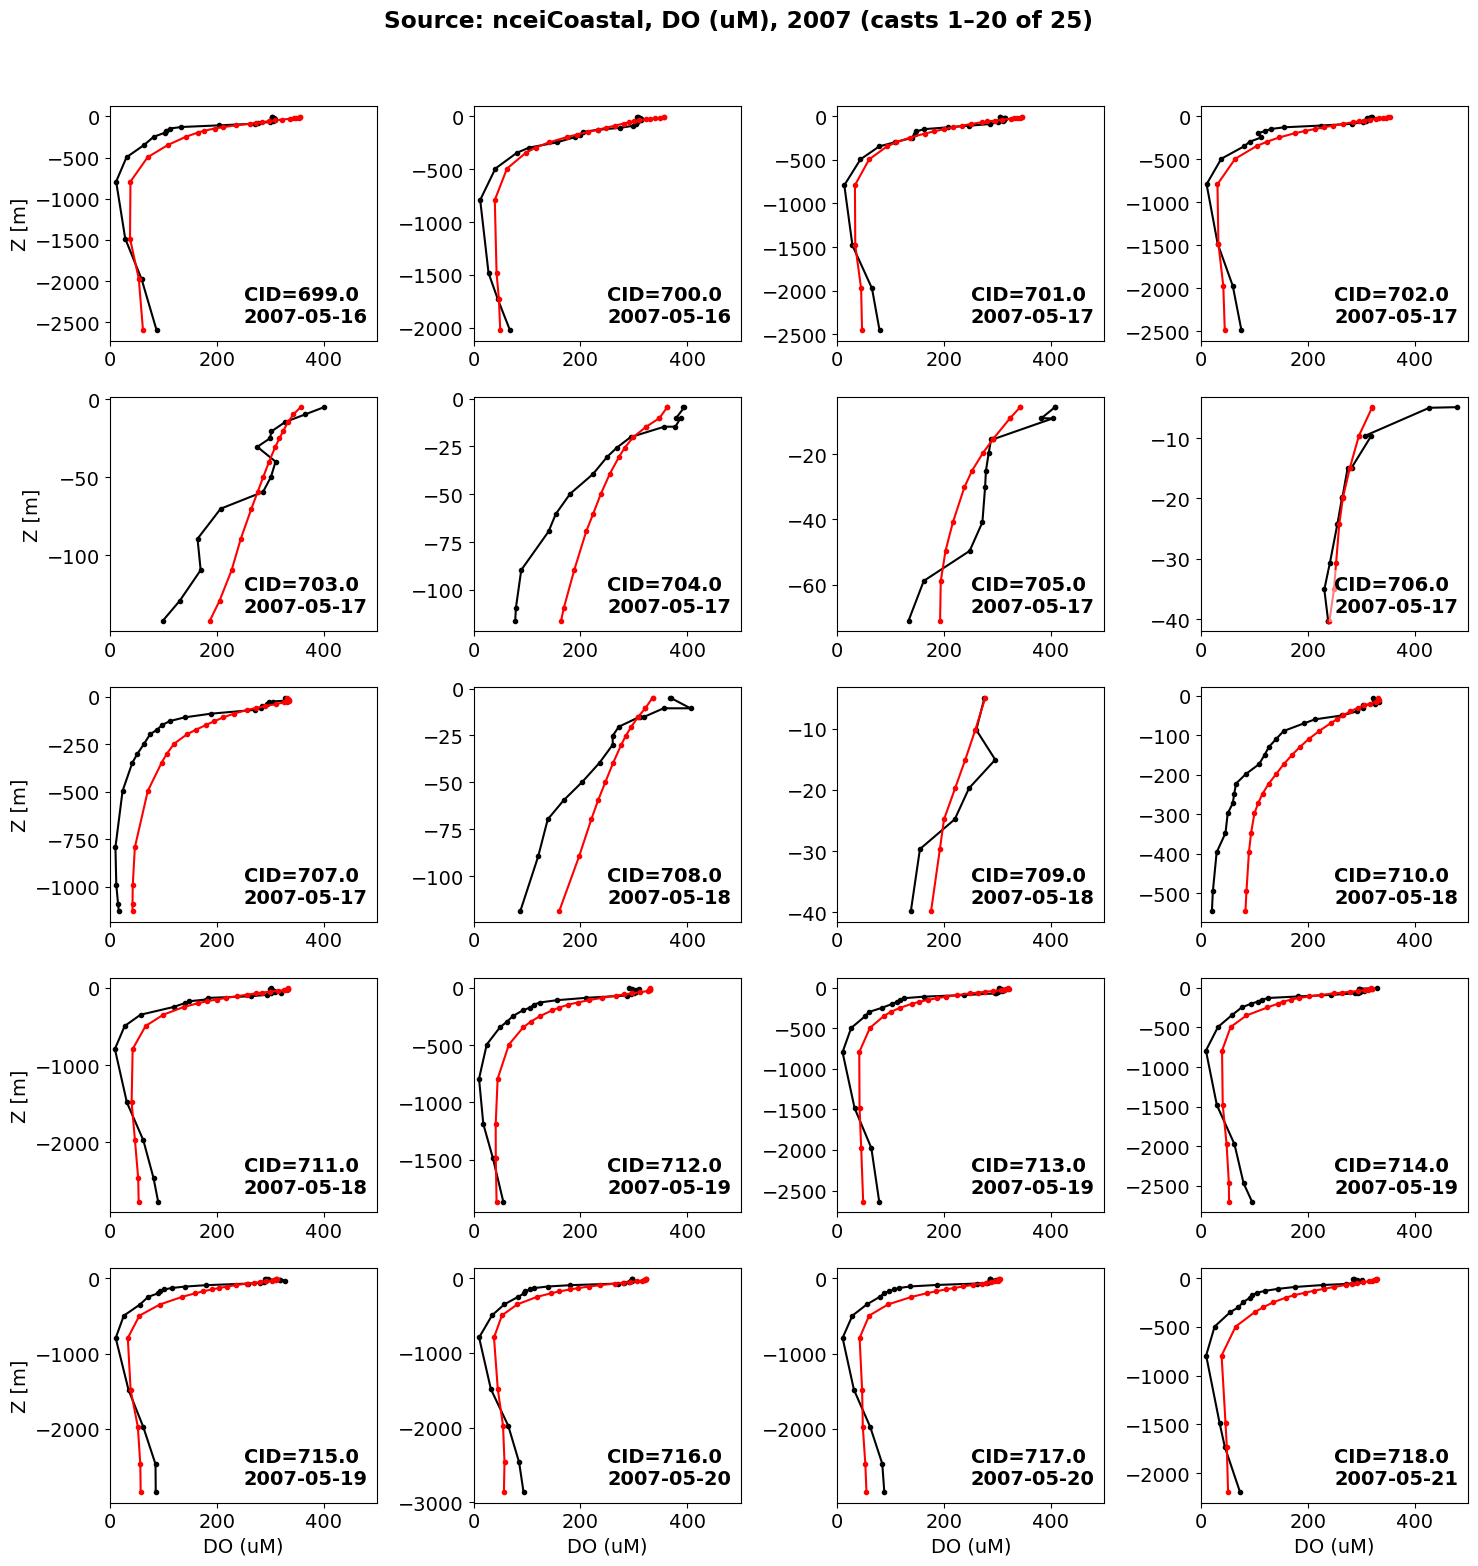

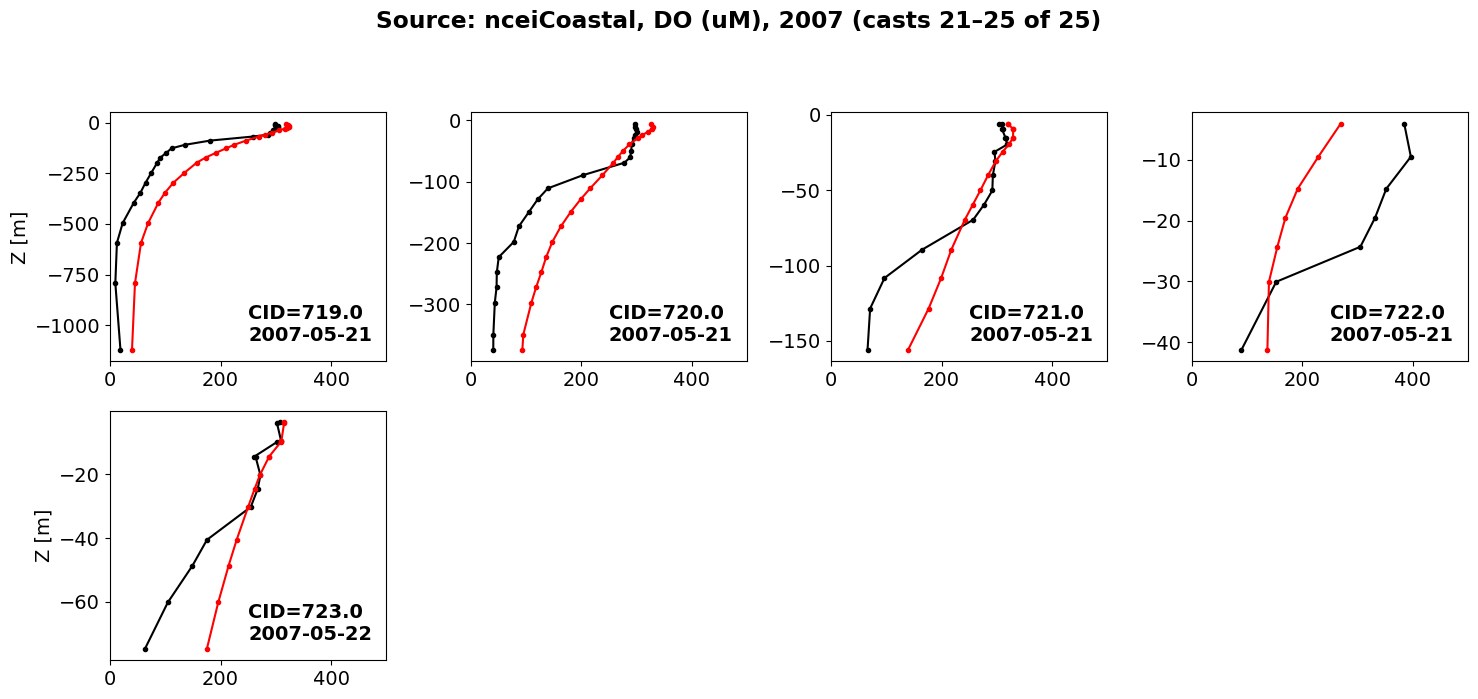

ncast: 41


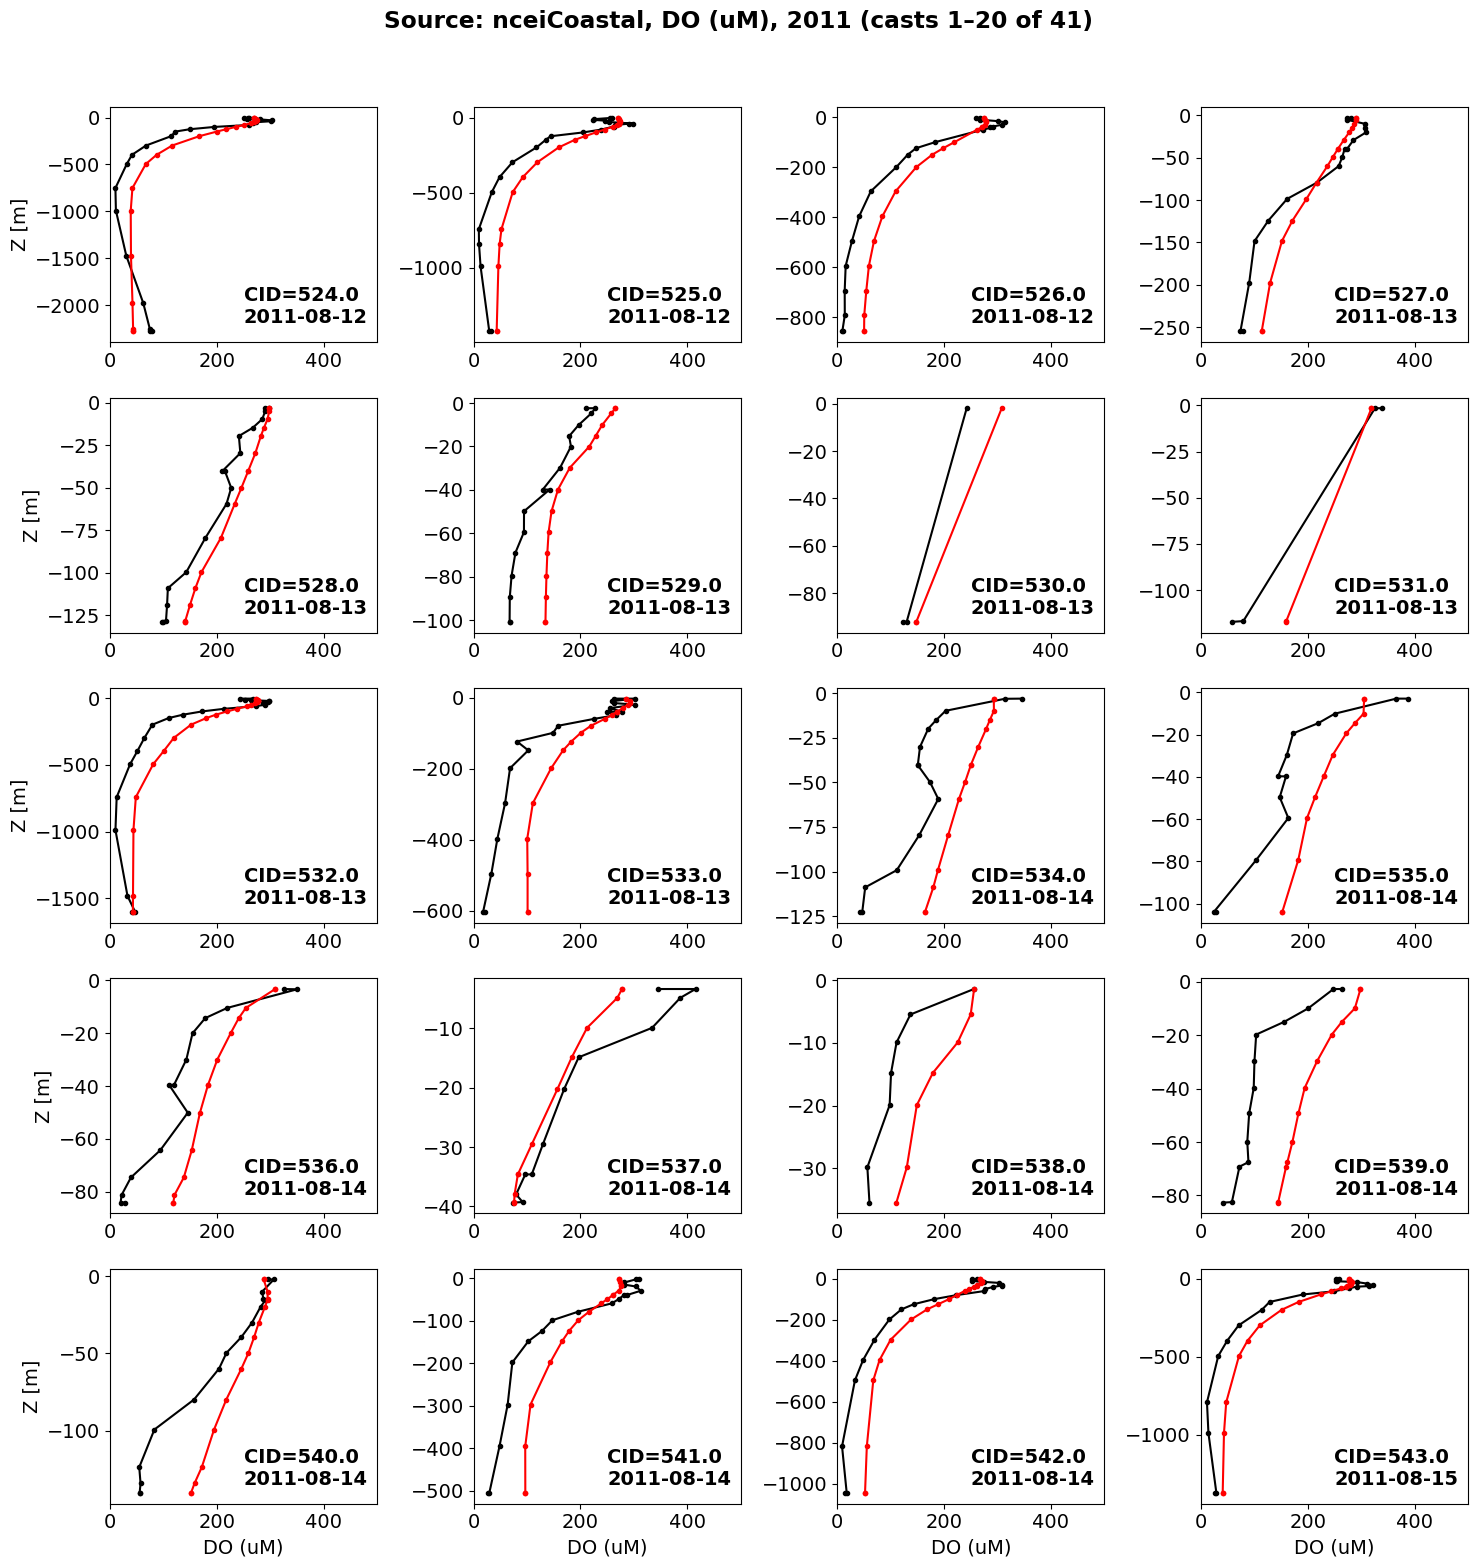

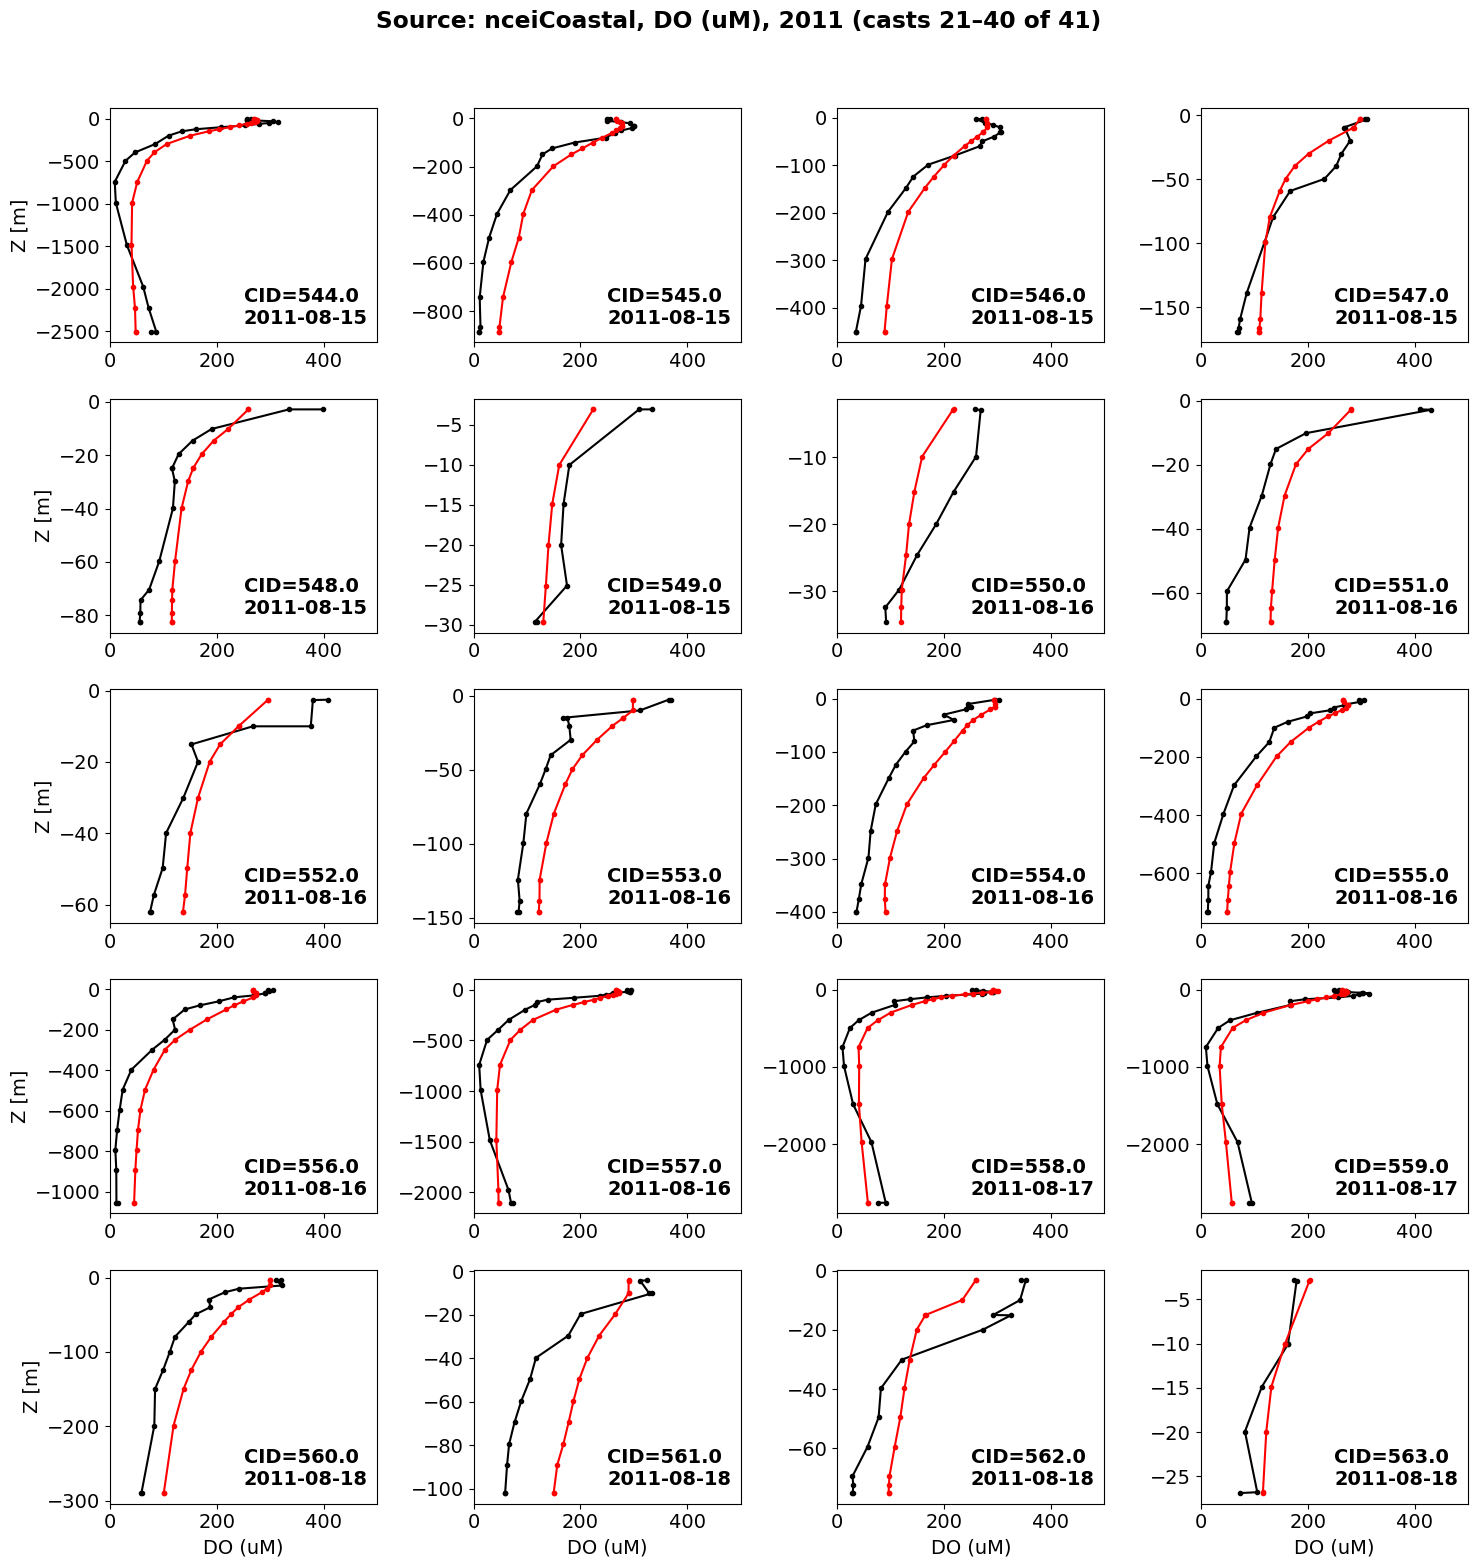

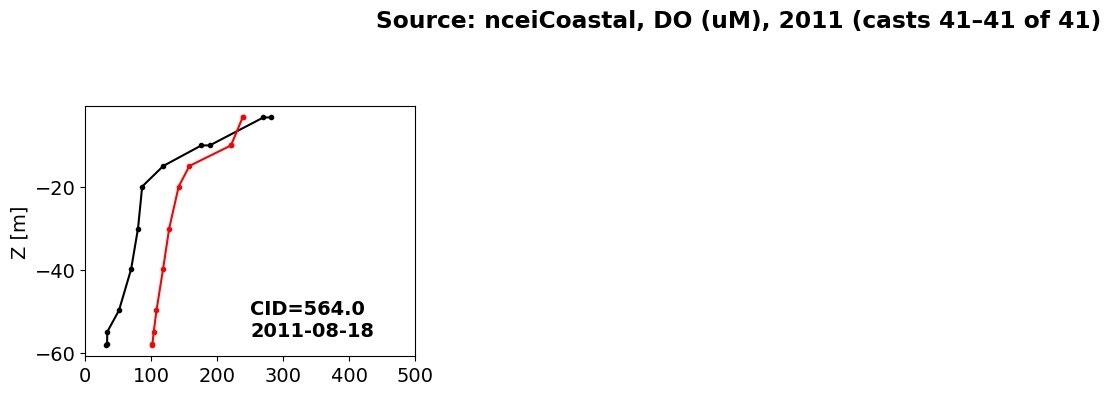

ncast: 54


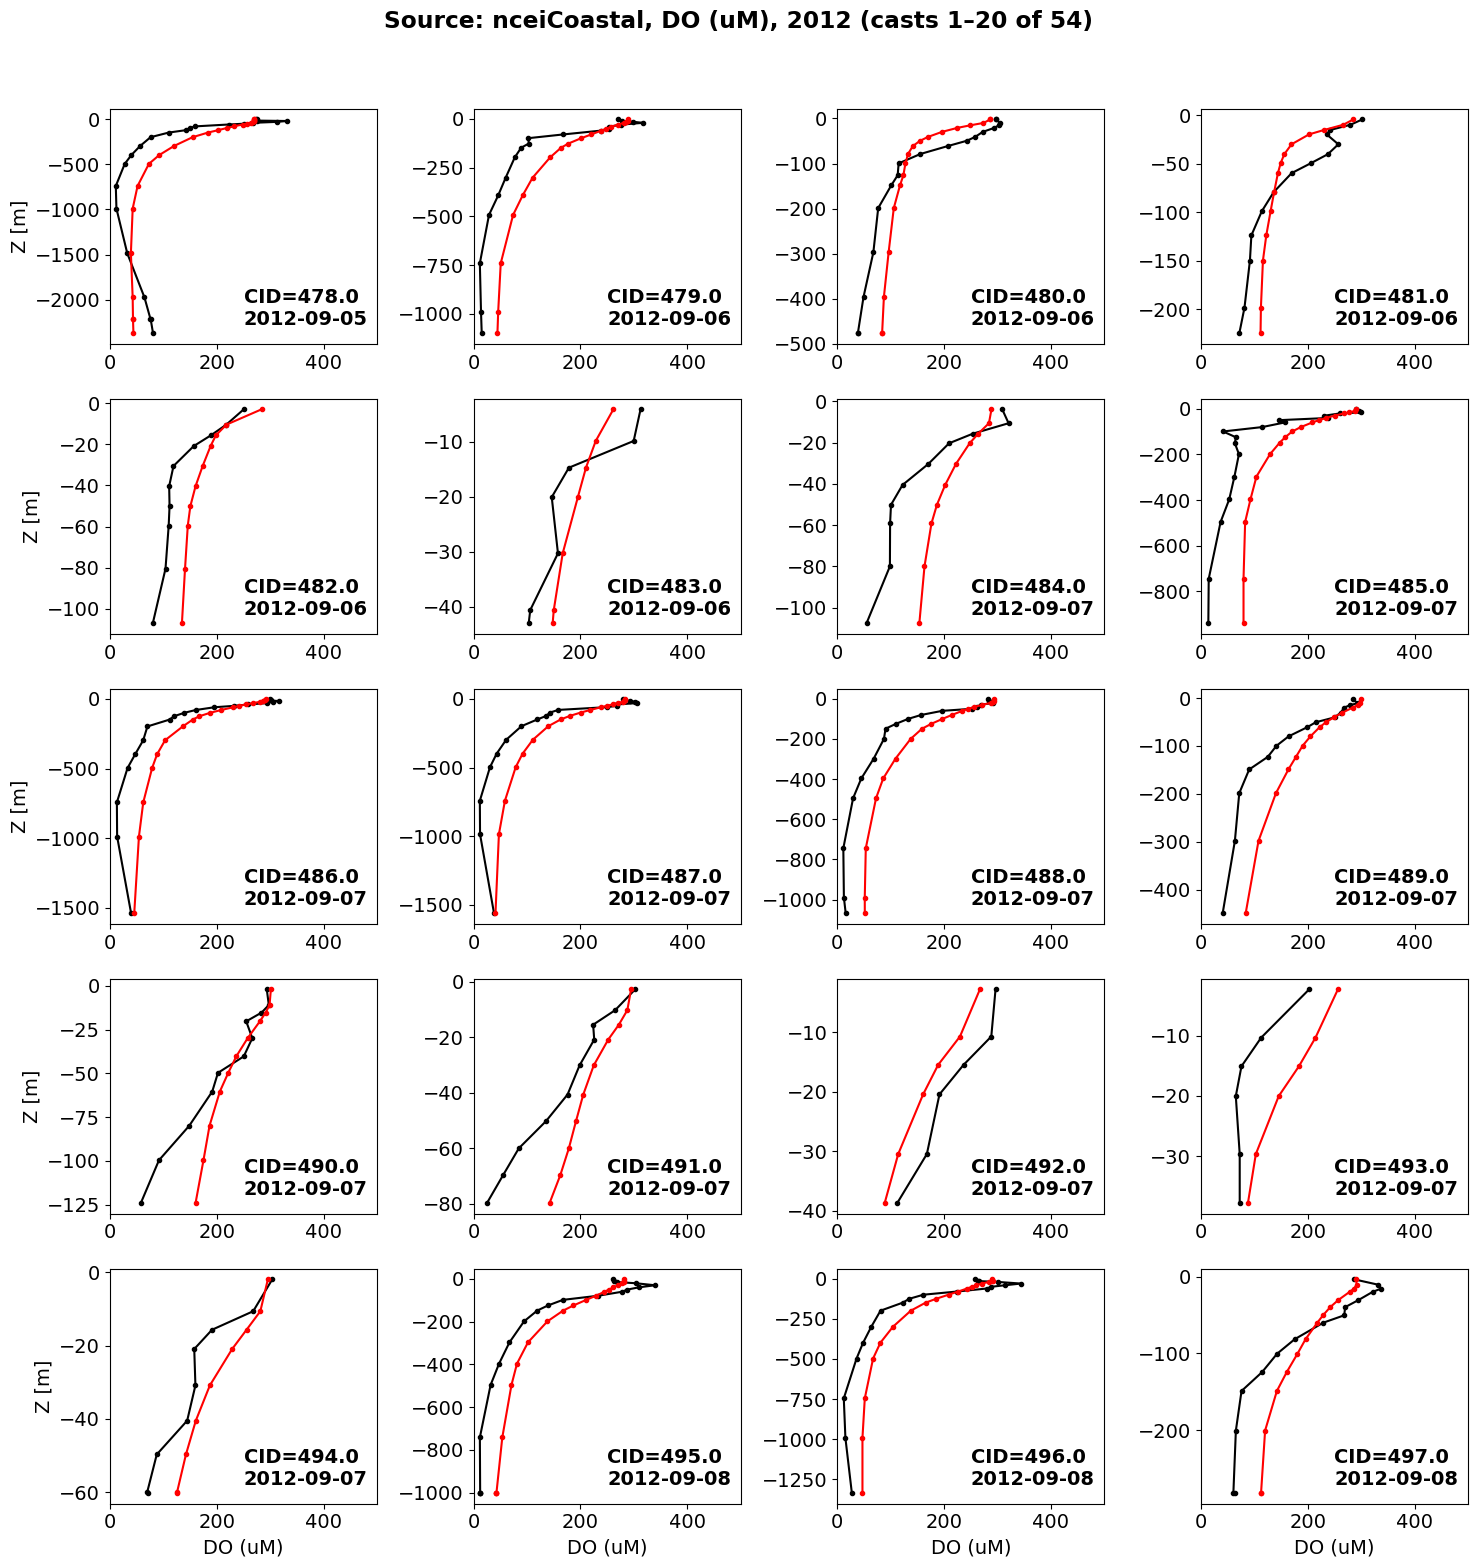

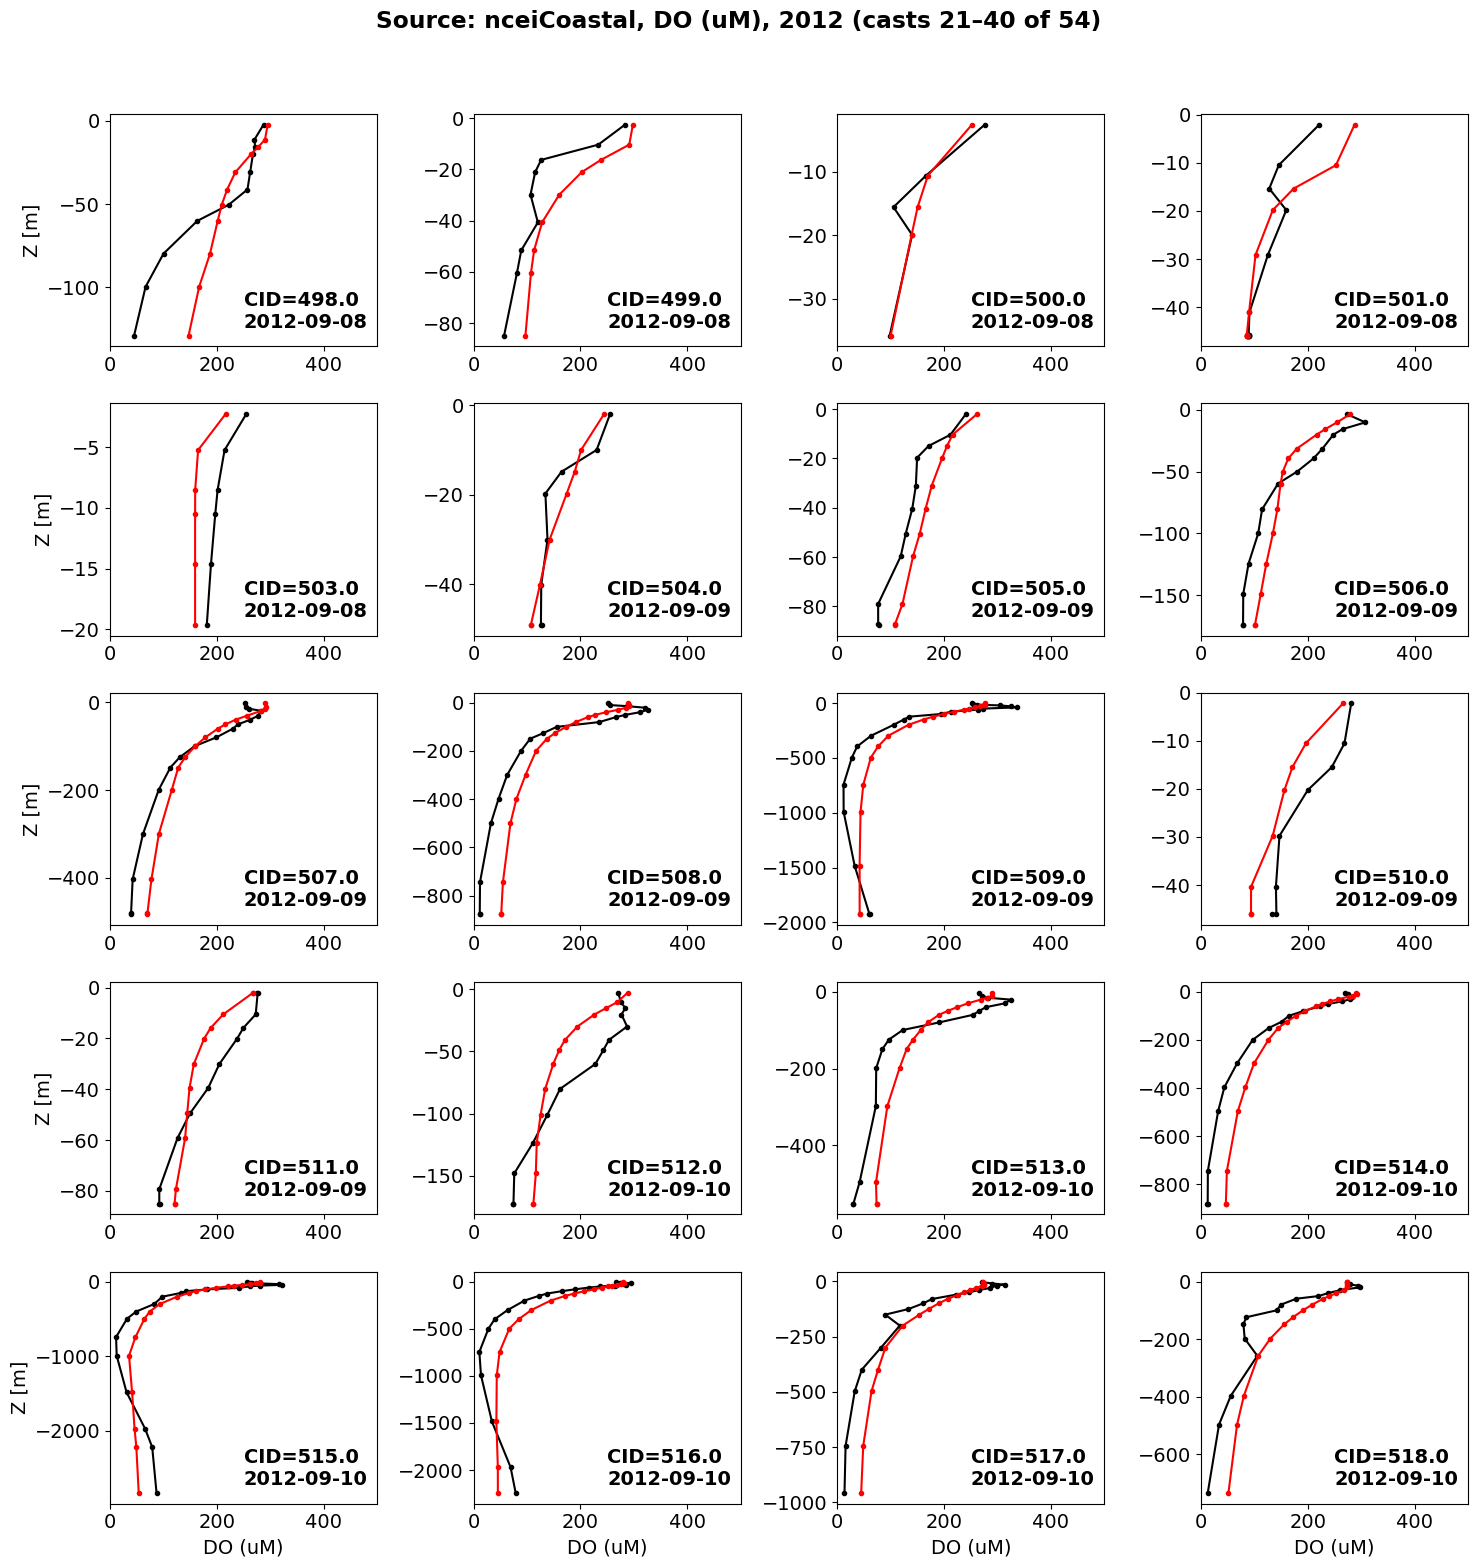

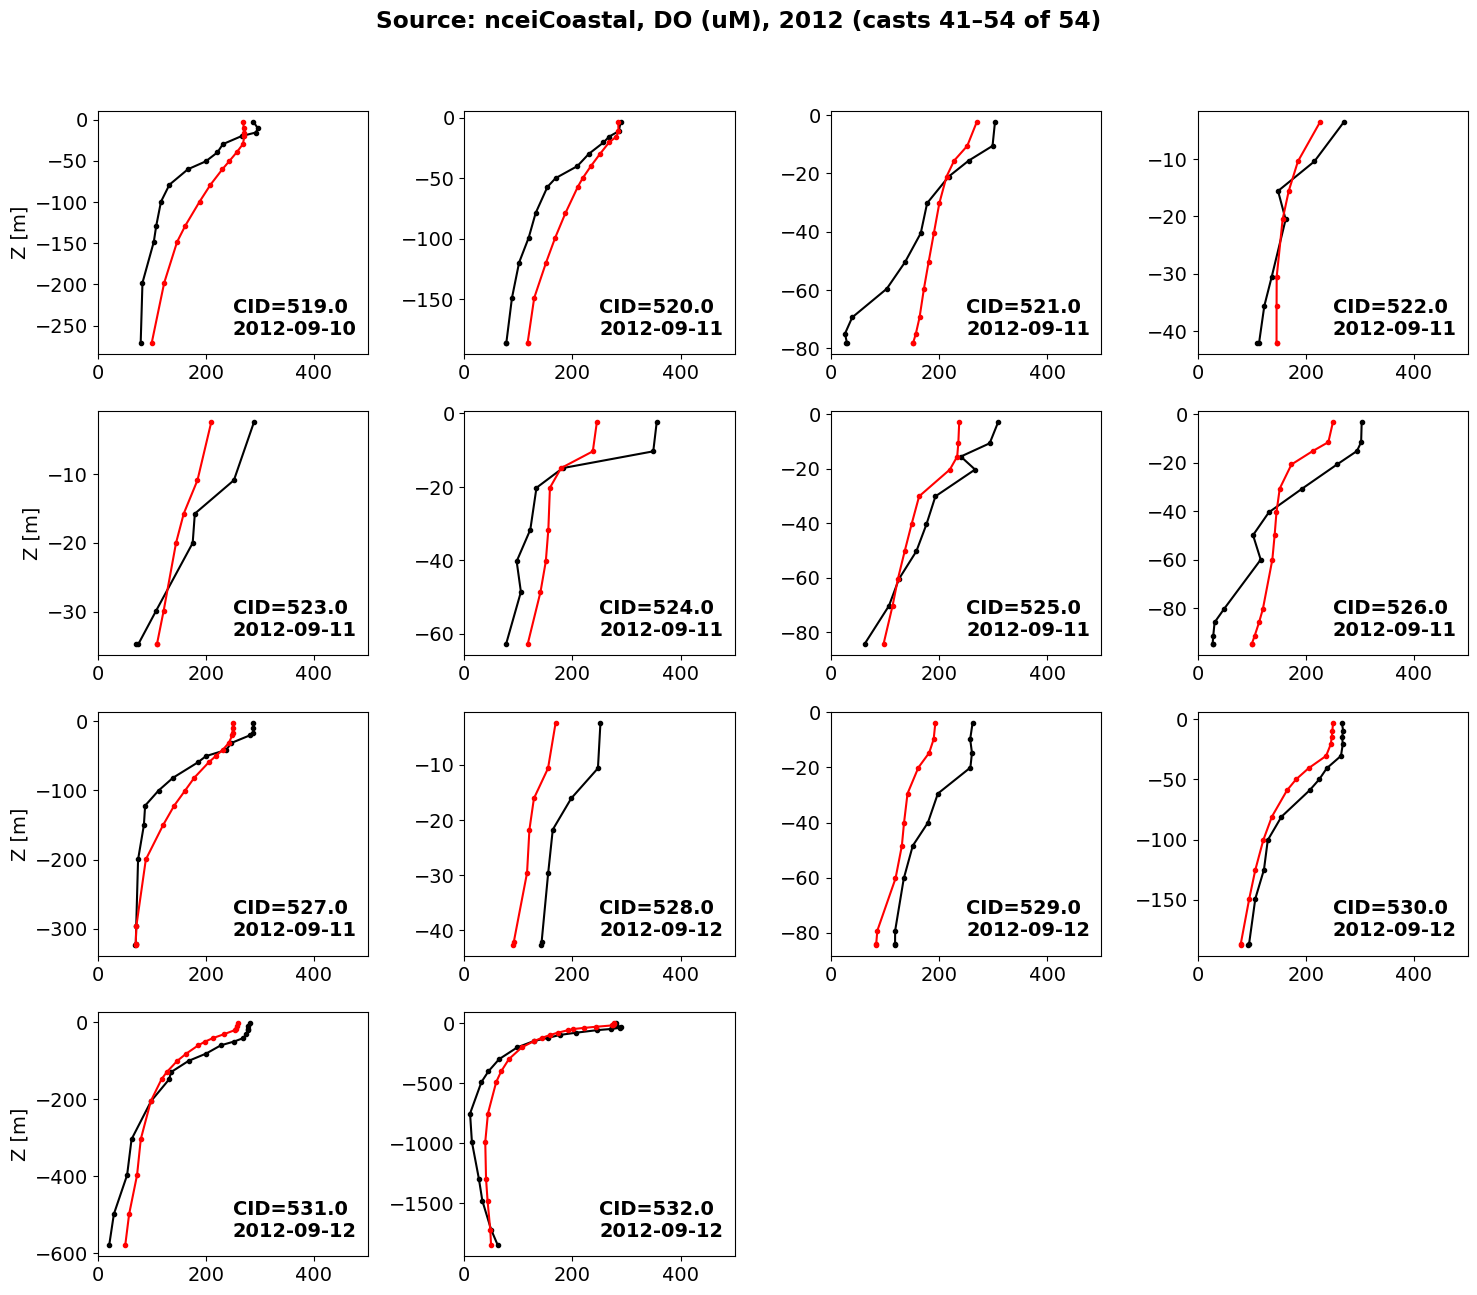

ncast: 48


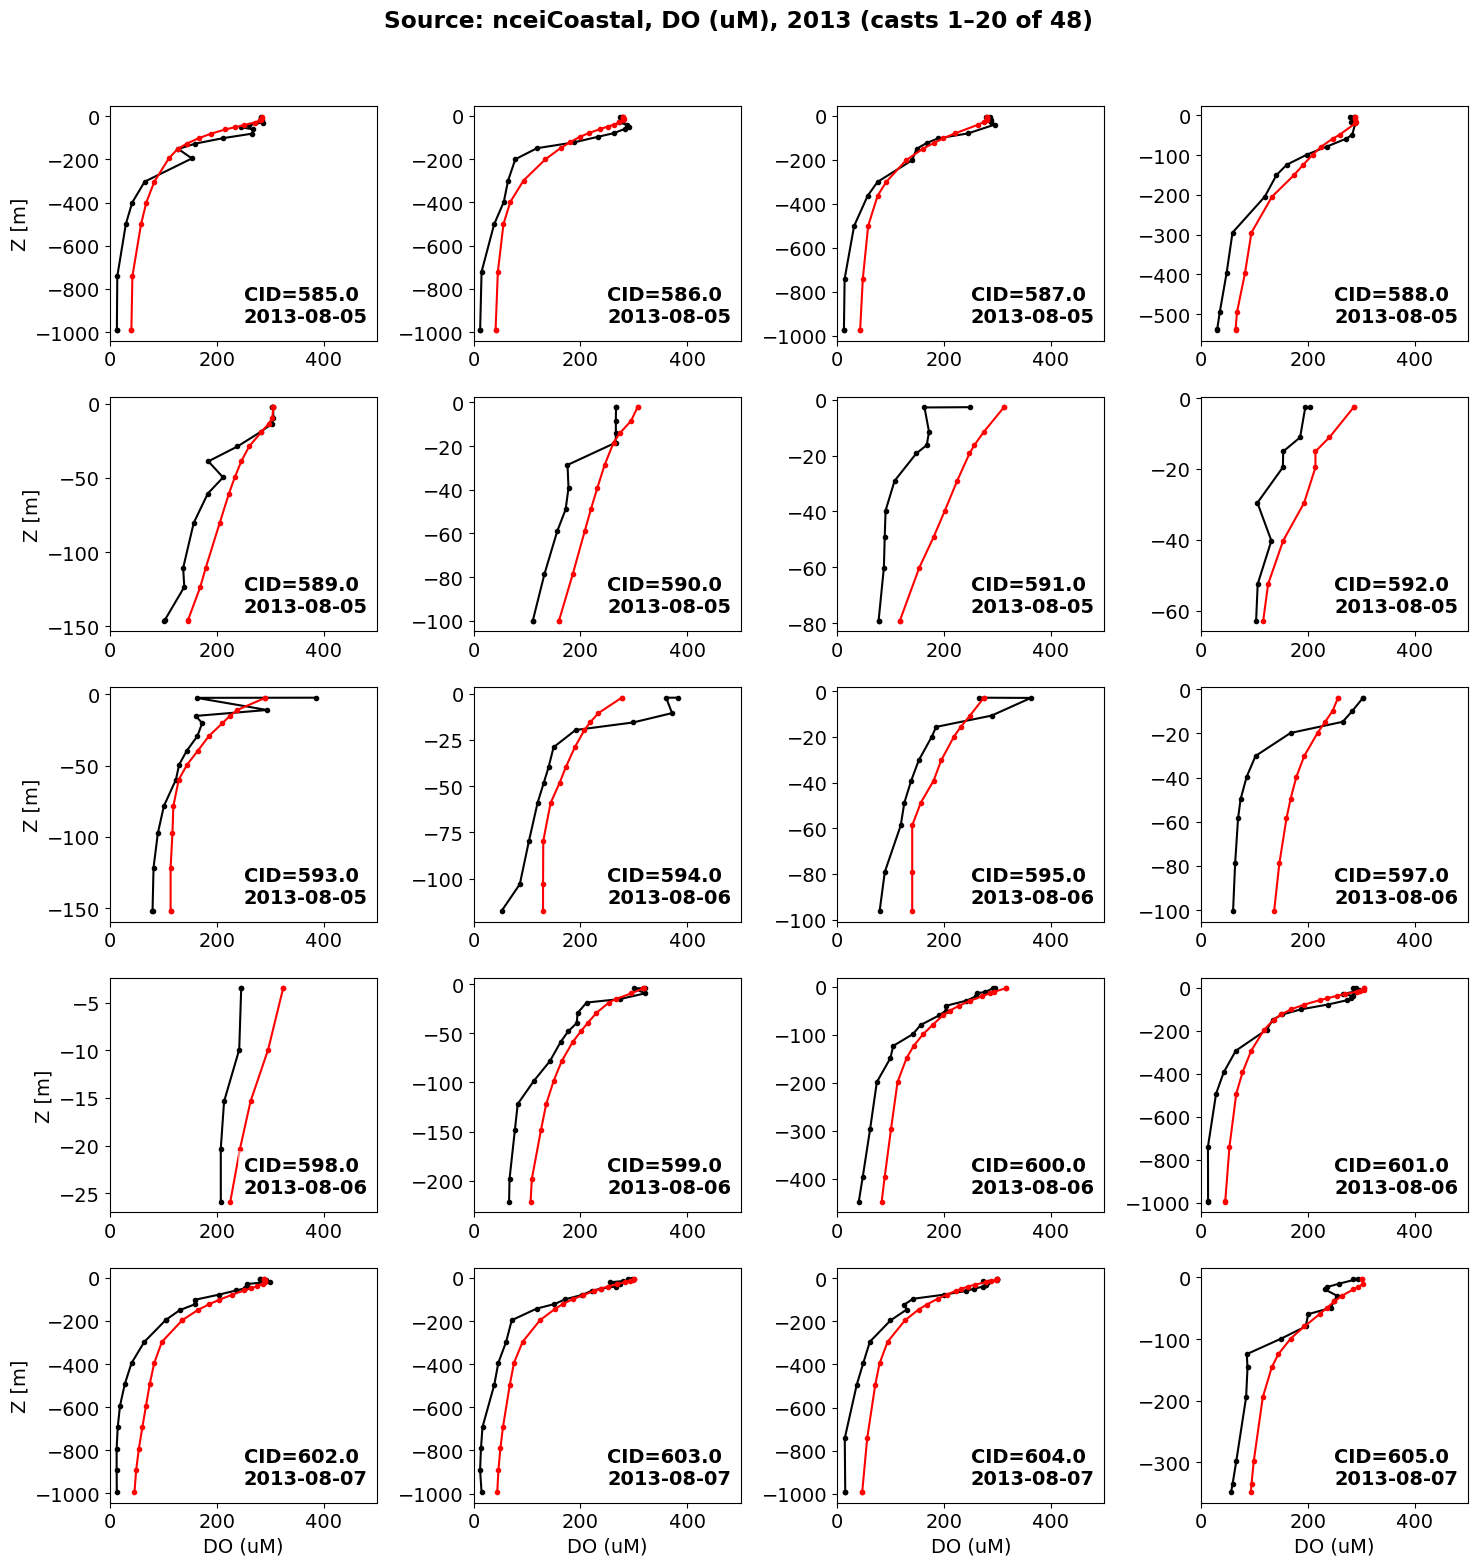

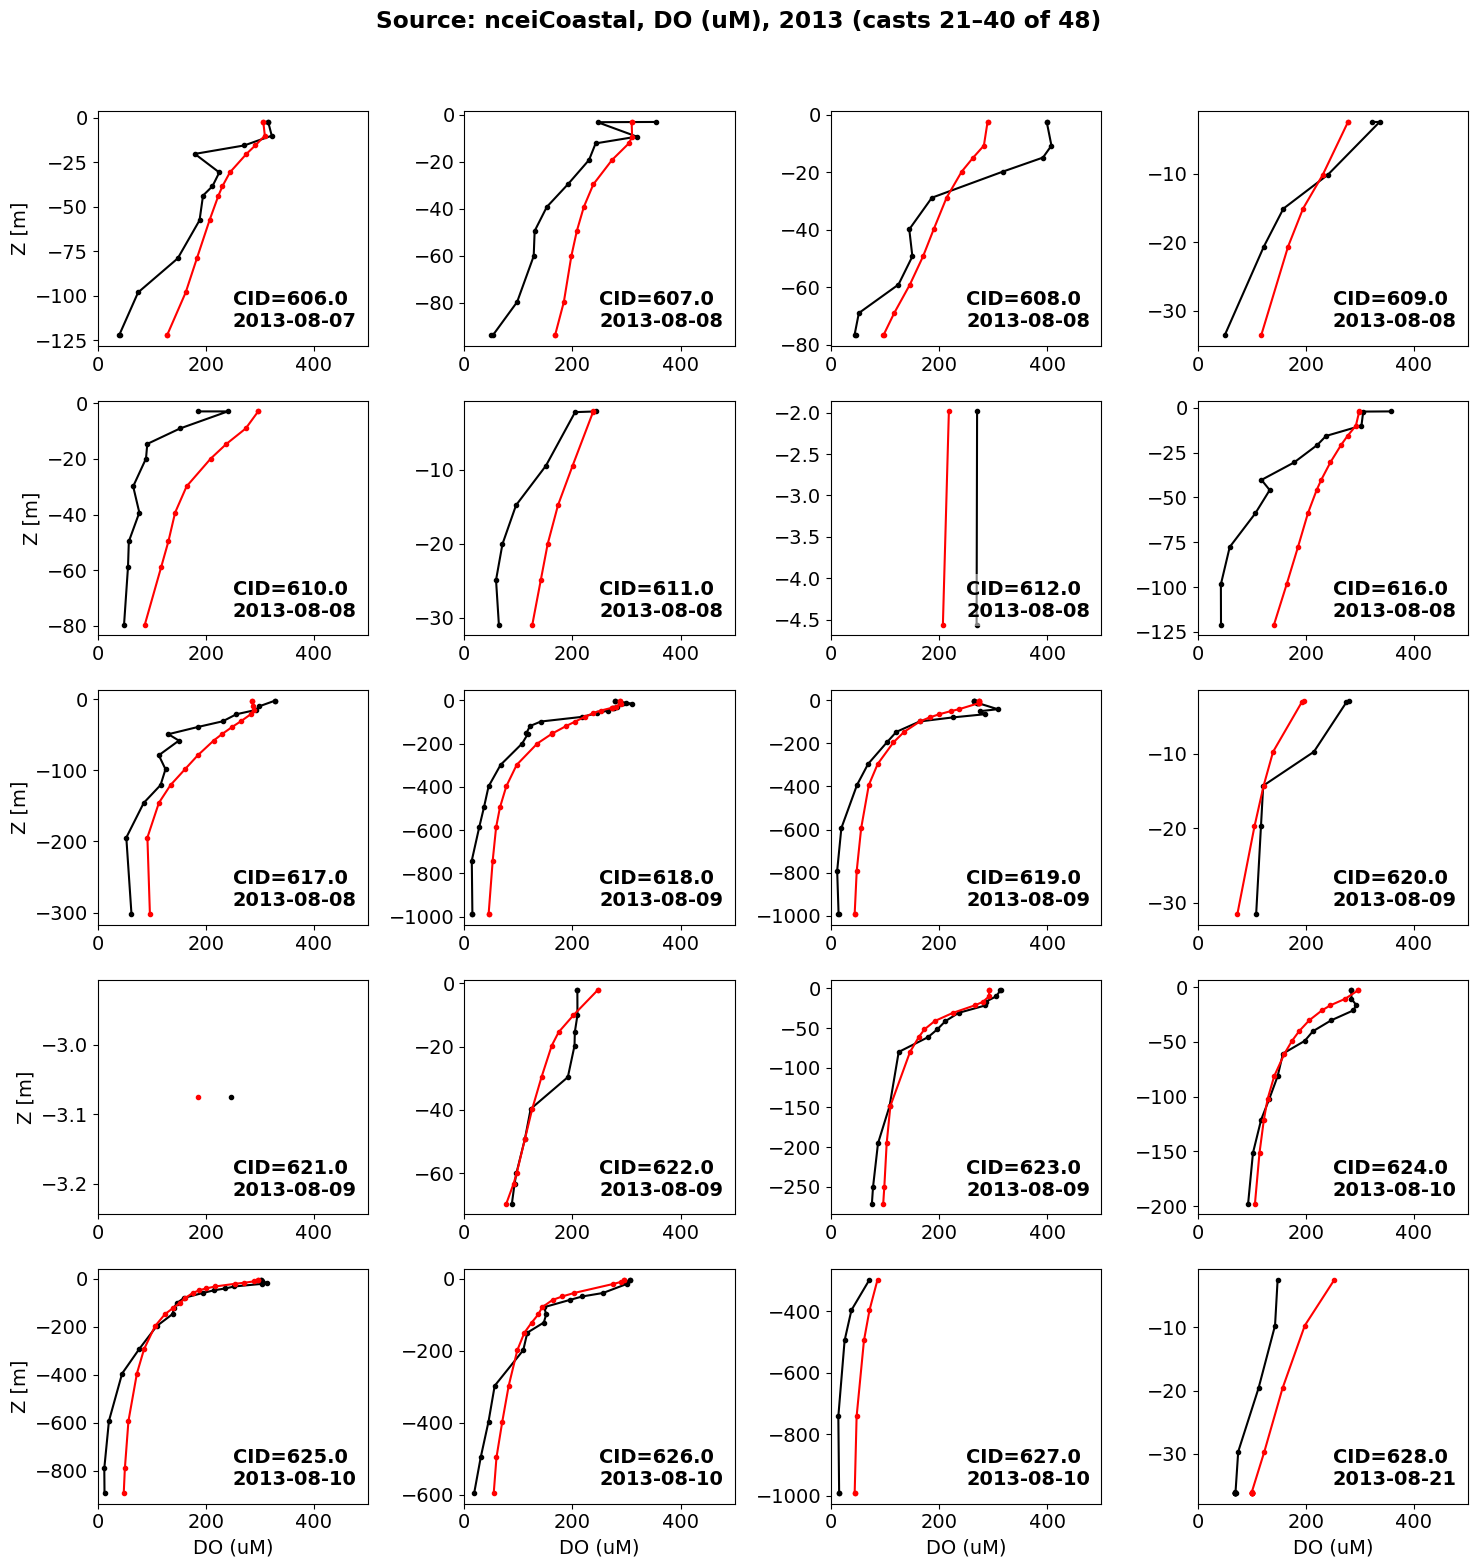

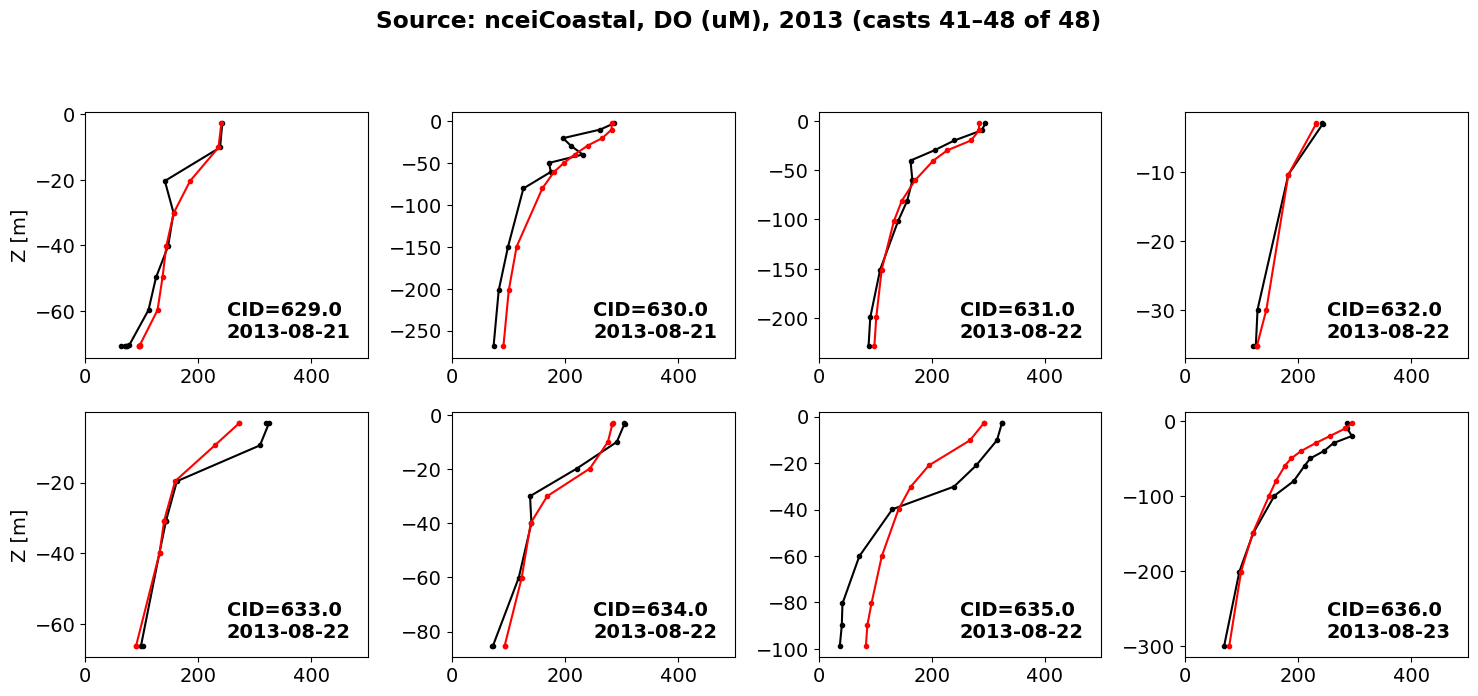

ncast: 46


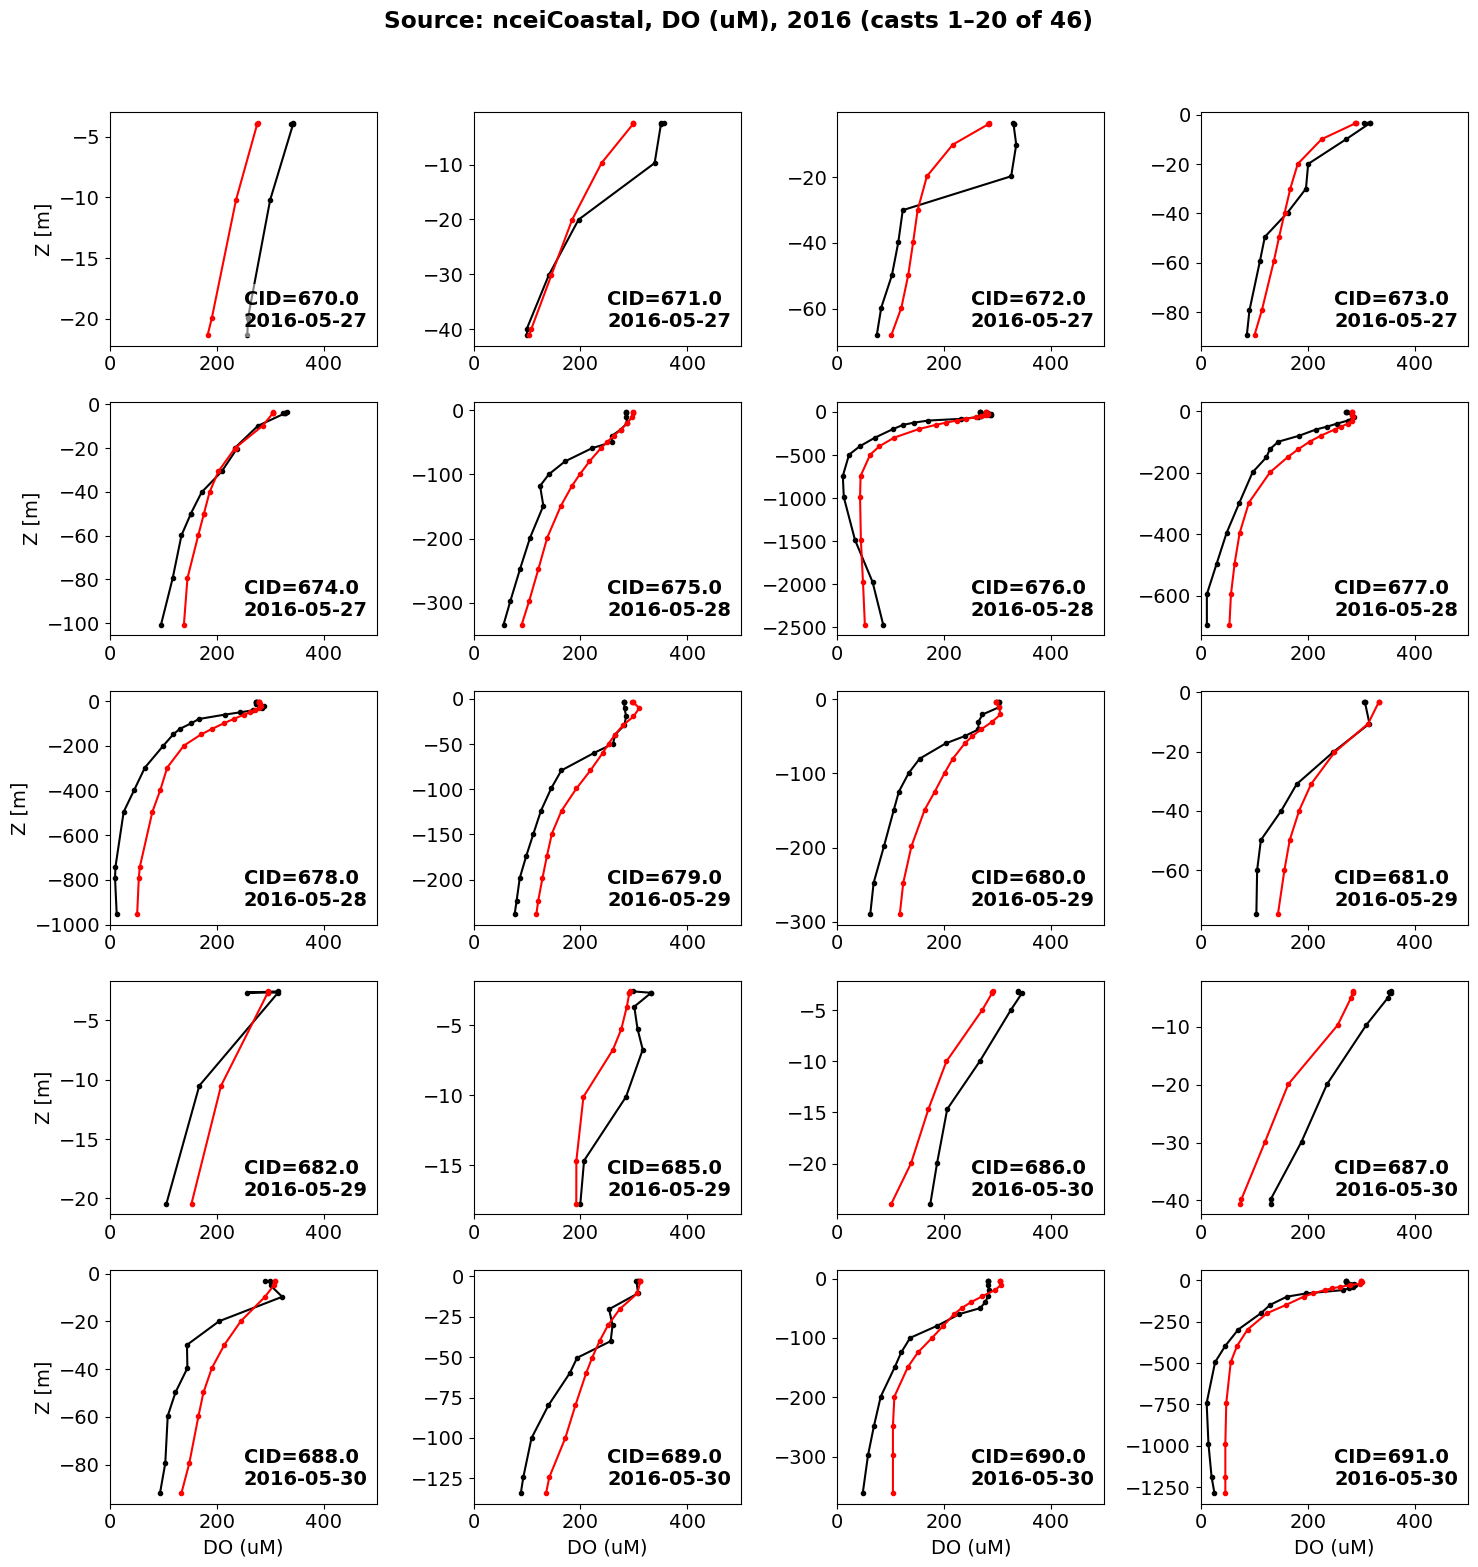

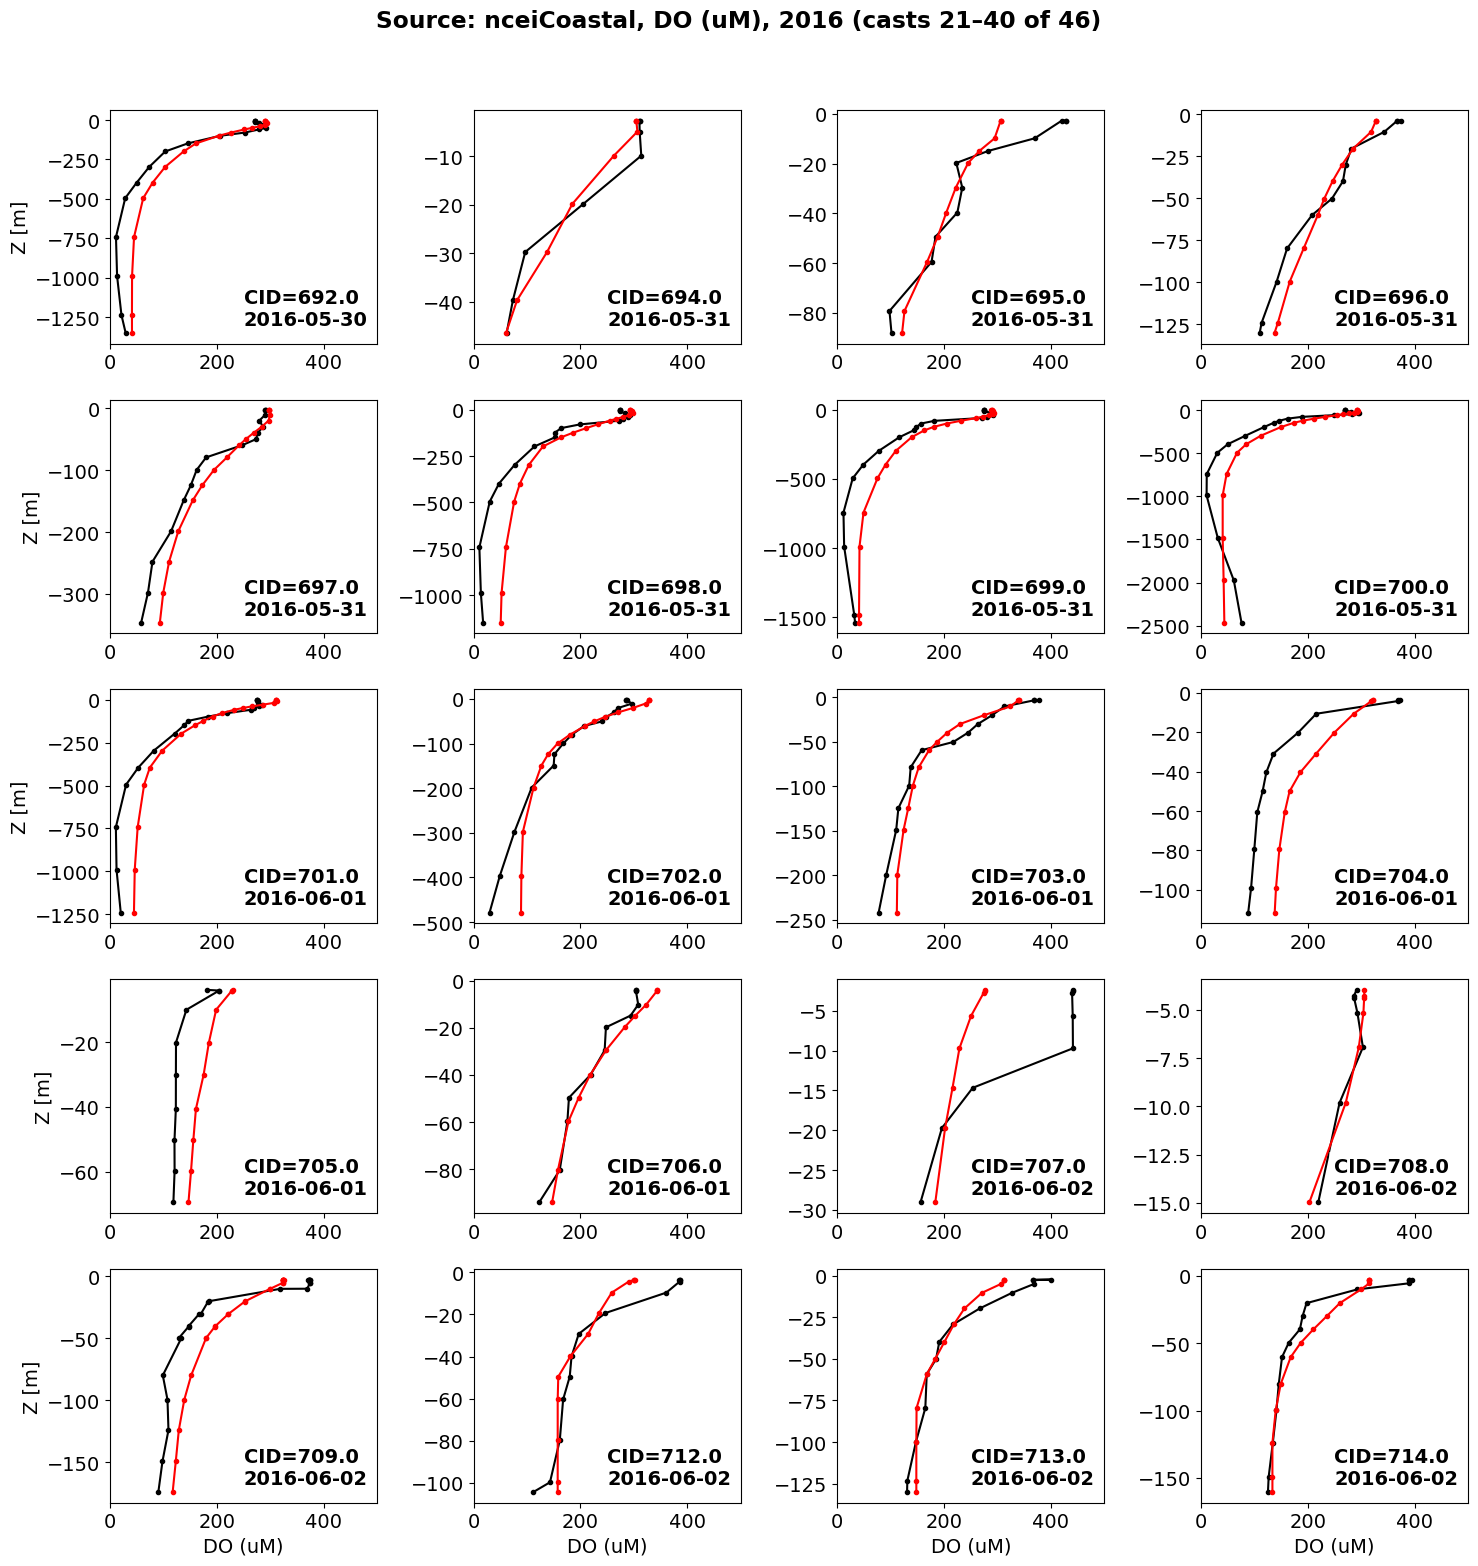

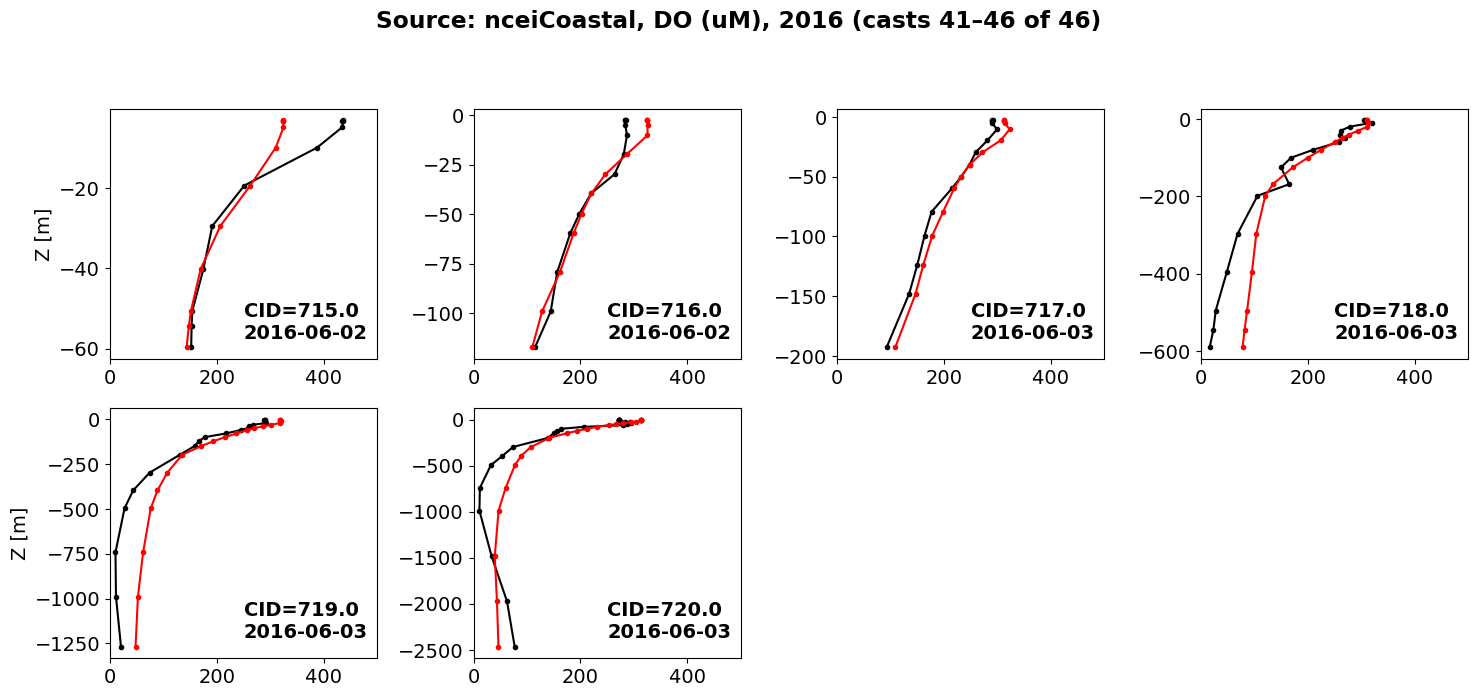

ncast: 38


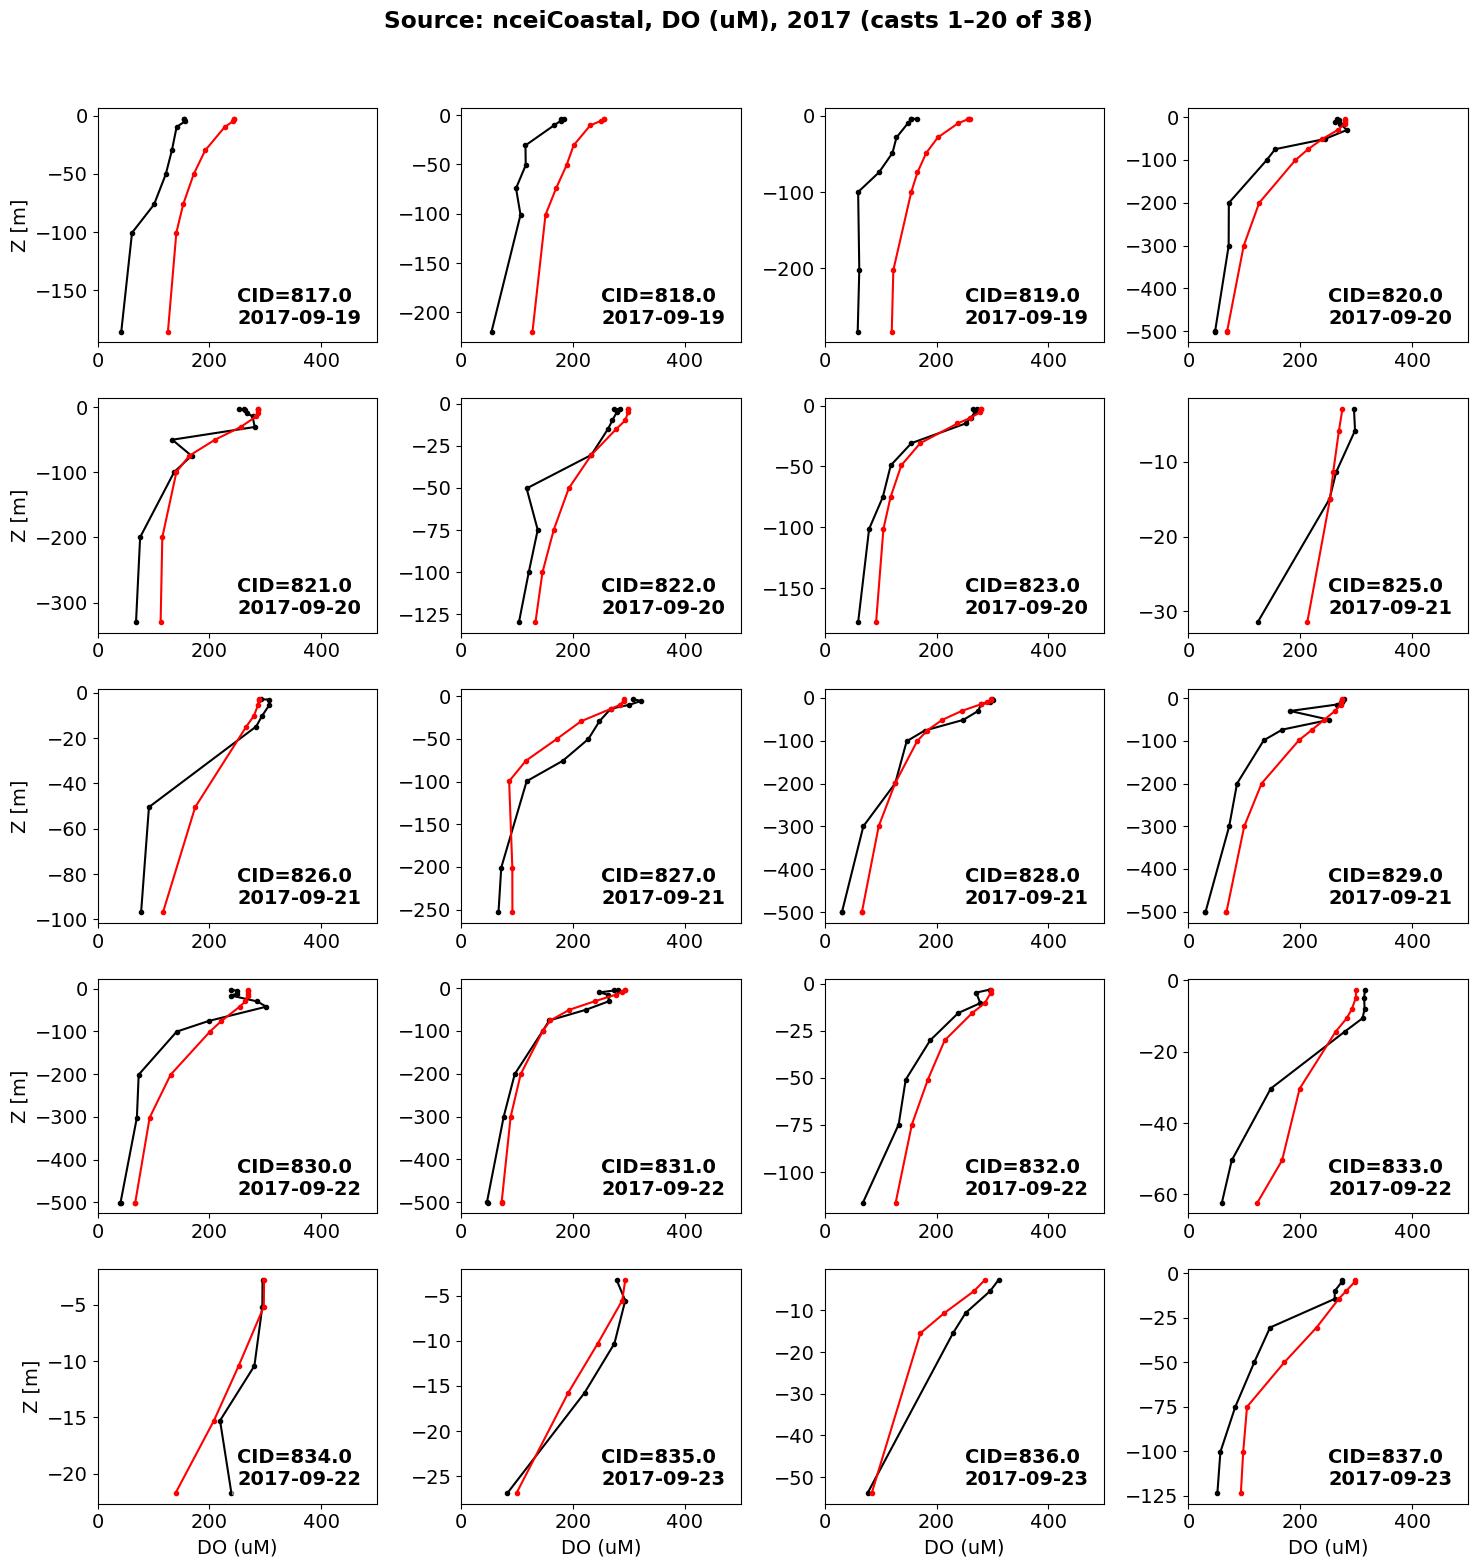

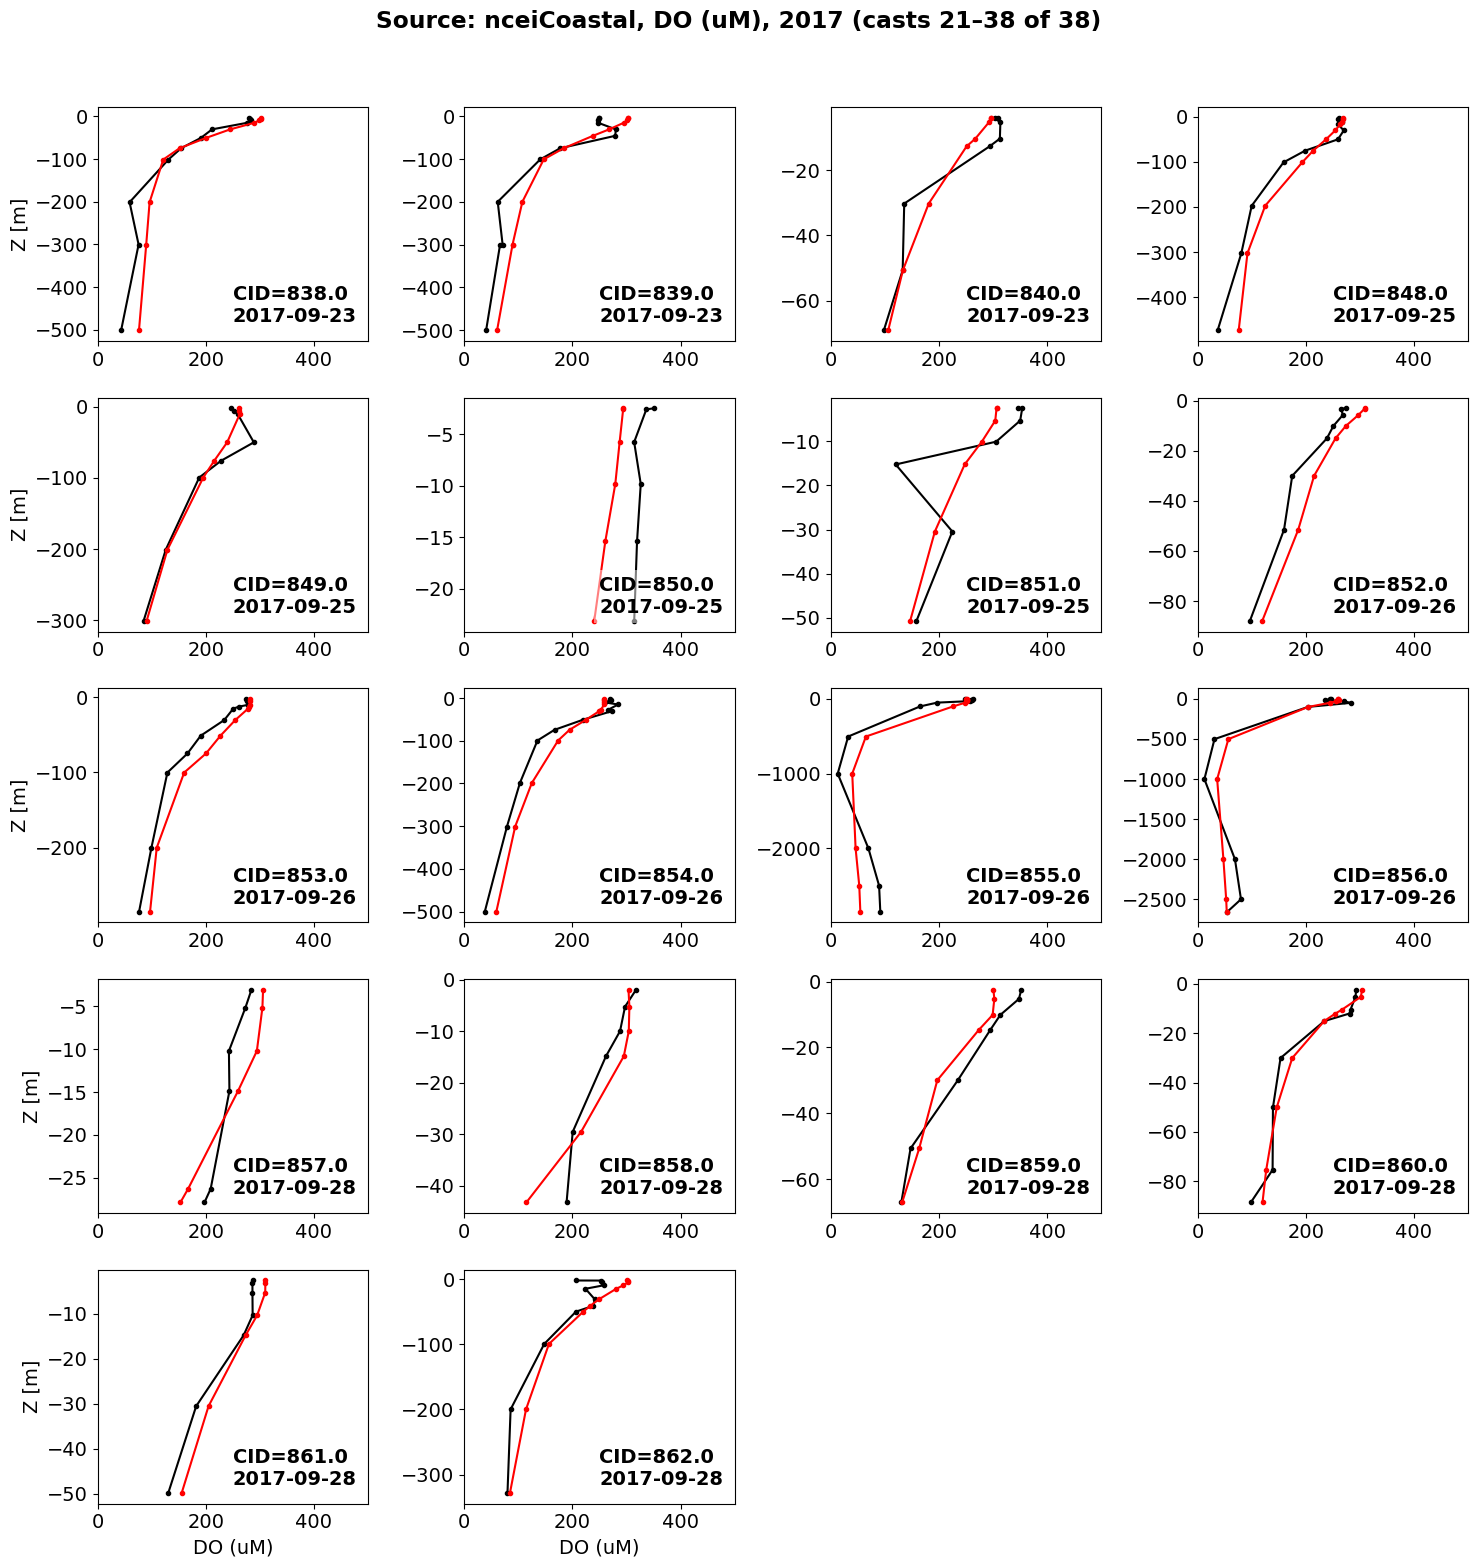

ncast: 47


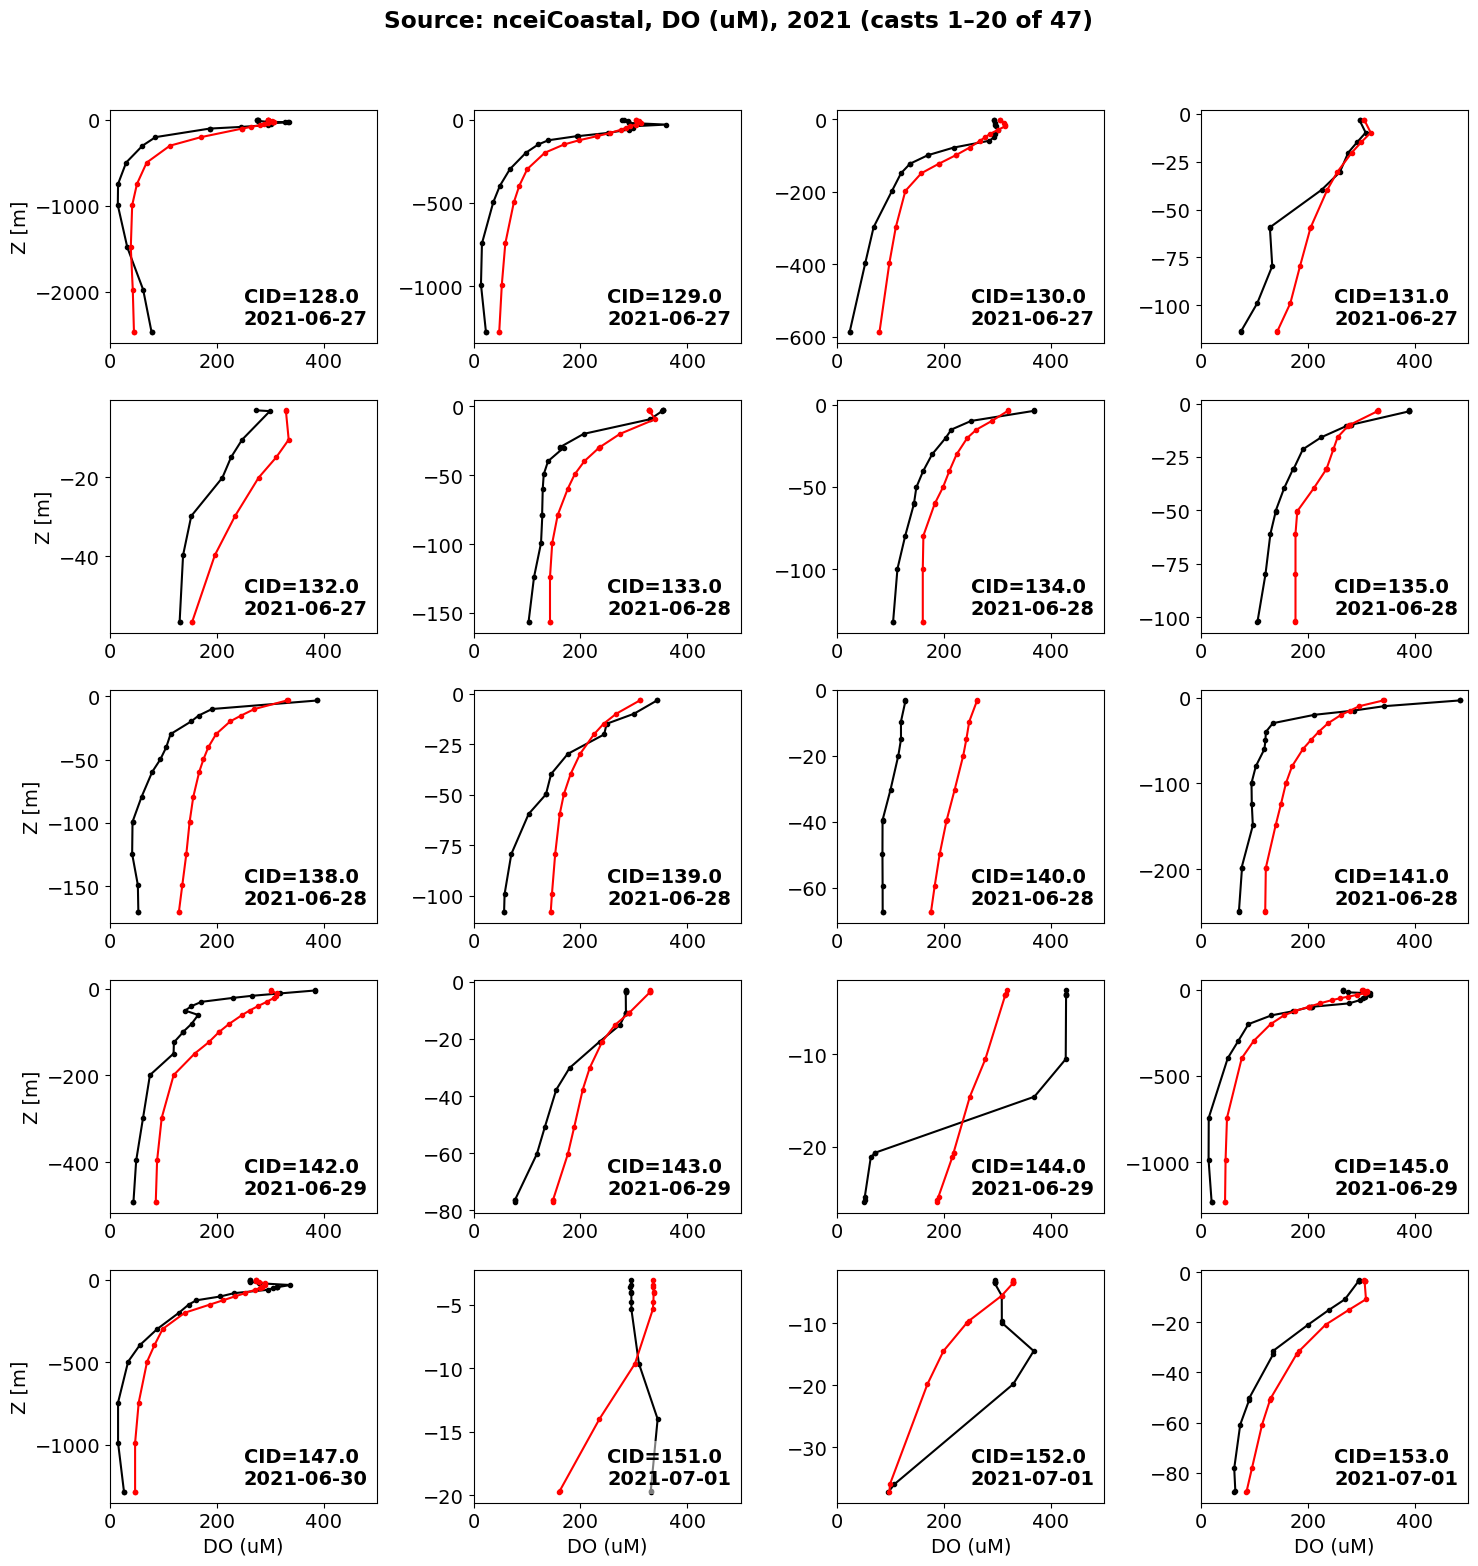

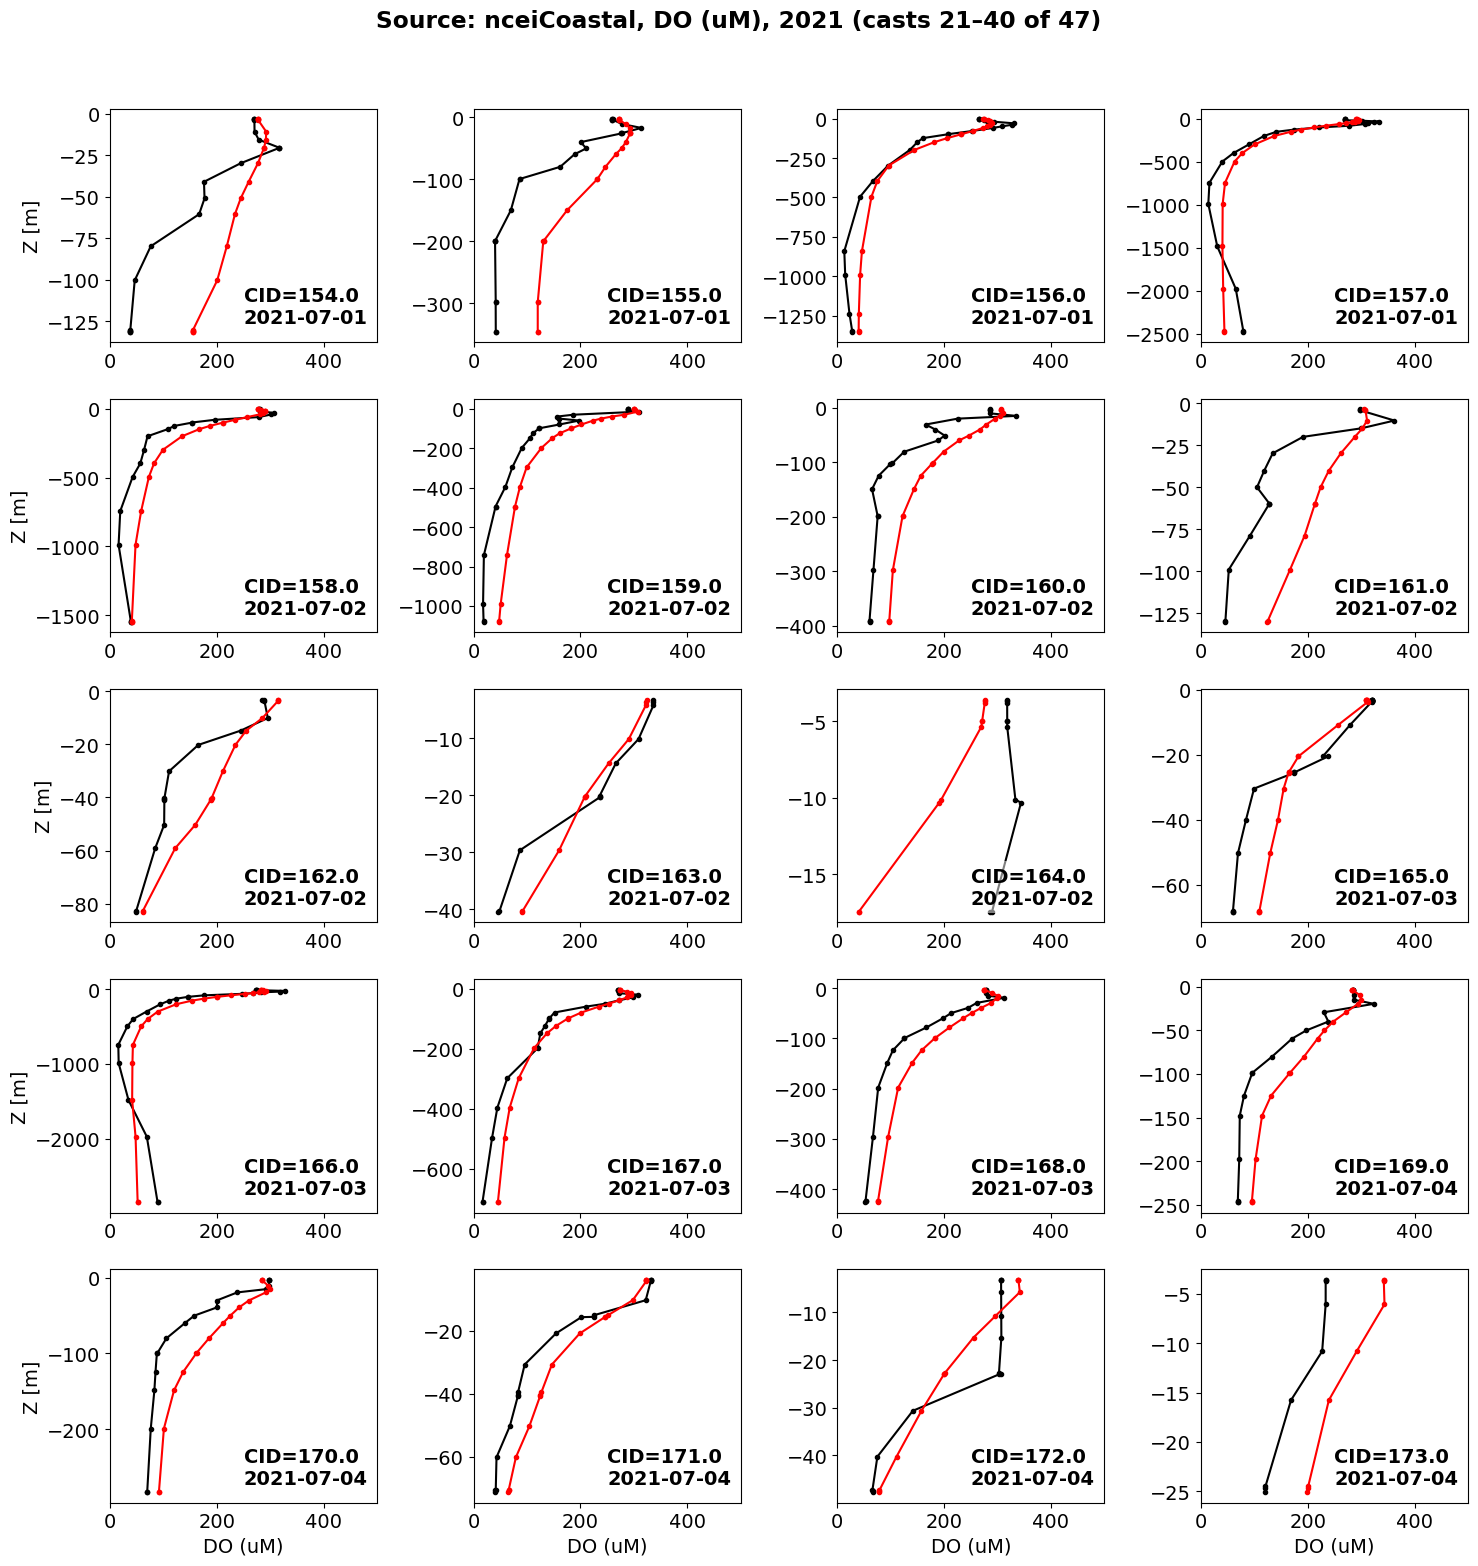

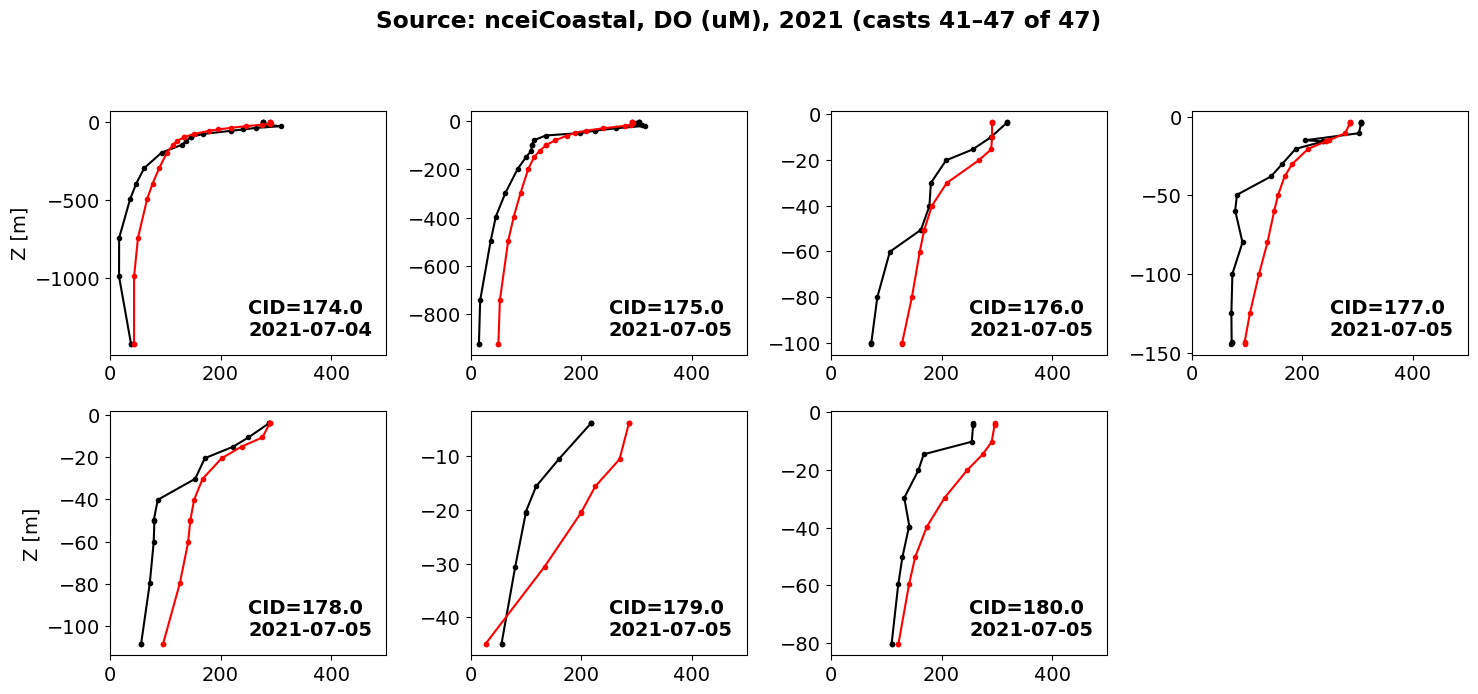

In [5]:
# specify input (created by data_combine_cleanup_and_plot_cast_seasonal.py)
if otype == 'ctd':
    in_fn = in_dir / ('combined_' + otype + '_all_' + '1998-2022' +'.p')
else:
    in_fn = in_dir / ('combined_' + otype + '_all_' + '1993-2021' +'.p')
print(in_fn)
df_dict = pickle.load(open(in_fn, 'rb'))
from scipy.signal import savgol_filter
for year in yr_list:
    year = int(year)
    # Create a dataframe dictionary for this year/source
    df_dict_year = {}
    # Keep only the assigned source for every dataset
    for gtx in df_dict.keys():
        a = df_dict[gtx]
        mask = (
            a['source'].eq(source)
            & a['time'].dt.year.eq(year)
        )
        df_dict_year[gtx] = a.loc[mask].copy()

    # plotting
    plt.close('all')

    nrow = 5
    ncol = 4
    ncast_per_fig = nrow * ncol  # 20

    cid_list = df_dict_year['obs']['cid'].dropna().unique()
    ncast = len(cid_list)
    print('ncast:', ncast)
    for fig_num, start in enumerate(range(0, ncast, ncast_per_fig), start=1):

        cid_subset = cid_list[start:start + ncast_per_fig]

        plt.close('all')
        pfun.start_plot(figsize=(15, 16))

        fig, axes = plt.subplots(nrow, ncol, squeeze=False)
        axes = axes.flat

        for ii, cid in enumerate(cid_subset):
            ax = axes[ii]

            obs_cast = df_dict_year['obs'].loc[df_dict_year['obs']['cid'] == cid]
            date = obs_cast['time'].iloc[0].strftime('%Y-%m-%d')

            for gtx_key, df in df_dict_year.items():
                # cast = df.loc[df['cid'] == cid]
                cast = (
                    df.loc[df['cid'] == cid]
                    .sort_values('z')
                )
                if cast.empty:
                    continue

                x = cast[vn].to_numpy()
                y = cast['z'].to_numpy()

                if otype == 'bottle':
                    ax.plot(x, y, '-o', color=c_dict[gtx_key], ms=3)
                elif otype == 'ctd':
                    ax.plot(x, y, '-', color=c_dict[gtx_key], lw=2)


            ax.text(
                0.5, 0.08,
                f'CID={cid}\n{date}',
                transform=ax.transAxes,
                fontweight='bold',
                bbox=pfun.bbox
            )
            ax.set_xlim(lim_dict[vn])

            if ii % ncol == 0:
                ax.set_ylabel('Z [m]')
            # else:
            #     ax.set_yticklabels([])

            if ii // ncol == nrow - 1:
                ax.set_xlabel(vn)

        # Hide empty panels in the final figure
        for ax in axes[len(cid_subset):]:
            ax.set_visible(False)

        fig.suptitle(
            f'Source: {source}, {vn}, {year} '
            f'(casts {start + 1}–{start + len(cid_subset)} of {ncast})',
            fontweight='bold'
        )
        fig.tight_layout(rect=[0, 0, 1, 0.96])

        out_fn = fig_dir / f'{source}_{vn}_{year}_{otype}_Figure_{fig_num:02d}.png'
        fig.savefig(out_fn, dpi=300, bbox_inches='tight')

        plt.show()